# Hotspots em usinas solares com qualquer câmera: DINOv3 + assimilação de dados

**Pergunta:** dá para extrair as características de um hotspot de um jeito que **não dependa da câmera nem da
aquisição** (altitude, ângulo, calibração, paleta, resolução)? E quanto da perda entre usinas isso recupera?

**Método:** DINOv3 congelado + regressão logística, com a "inversão do operador de observação" da assimilação de
dados: temperatura relativa ao fundo de painel (ΔT_z) pintada numa paleta canônica, escala física de 3 cm/px,
correção de viés tipo VarBC, ganho tipo Kalman sobre a evidência física e viés de anotação por fonte.

**Como usar:** Colab com GPU (A100), secret `HF_TOKEN` com acesso ao DINOv3, a pasta `SCC0287_Solar_v3_dados` no
Drive e *Executar tudo*. Tudo fica em cache em `MyDrive/SCC0287_Solar_v3`; se a sessão cair, execute de novo.

Projeto Final de SCC0287 (ICMC/USP).

## Configuração
**Hipótese central:** depois de inverter o "operador de observação" (o jeito como cada câmera e cada voo
registram a cena), a decisão do modelo **não depende da câmera nem da aquisição**. Testamos isso de três formas:
1. **deixando uma fonte inteira de fora** (outra câmera, outro país, outro critério de anotação);
2. **perturbando de forma controlada** as imagens rotuladas (resolução, altitude, ruído, paleta, desfoque);
3. aplicando o modelo a fontes **nunca vistas** (Kaggle agregado, sem radiometria; Colômbia, câmera nova).

**Pausar e retomar:** tudo fica em cache no Drive (`MyDrive/SCC0287_Solar_v3`). Se a sessão cair, abra de novo e
*Executar tudo*: as etapas prontas são puladas.

In [1]:
# SMOKE_TEST=True: teste rápido com poucas imagens (CPU, DINOv2-S no lugar do DINOv3). False: execução completa.
SMOKE_TEST = False

CFG = dict(
    seed=42,
    pasta_drive="SCC0287_Solar_v3",
    pasta_dados="SCC0287_Solar_v3_dados",       # preparada localmente por preparar_dados_v3.py e enviada ao Drive
    backbone="dinov3_b16",                      # "dinov3_s16" é a opção mais leve
    escala=2,                                   # entrada ampliada 2x: patch de 16 px cobre 8 px da imagem
    escala_lim=(0.75, 3.0),                     # limites da escala total na variante 3 cm/px
    batch=8,
    fontes_loso=["PVHSD", "P16", "P17", "P18"],
    frac_val=0.2,                               # grupos de validação dentro das fontes de treino
    frac_in=(0.6, 0.2, 0.2),                    # referência "mesma fonte": treino/val/teste por grupo
    variantes=["R0", "R1", "R2"],               # entradas do backbone (ver seção 4)
    dim_pca=256,                                # features projetadas por PCA (ajustada só nas fontes de treino)
    neg_dificeis=64, neg_aleatorios=128,        # banco de treino por imagem
    frac_neg_aval=0.05,                         # células negativas amostradas para as métricas (com peso)
    max_celulas_painel=1500,
    janela_fundo=9,                             # janela da mediana de painel (grade reduzida 4x = 36 px)
    z_faixa=(-3.0, 8.0),                        # faixa do ΔT_z na pseudo-cor canônica
    epocas=12, lr=2e-3, wd_w=1e-4,                # (épocas/lr: só a máscara de painel)
    iter_lbfgs=300, l2_w=1e-5, l2_assim=1e-4,     # cabeças R0–R5: L-BFGS em lote completo (L2 validada em testar_cabeca.py)
    K_max=3.0,                                  # escala do ganho de Kalman (logit por unidade de ΔT_z)
    qc_dz_min=1.0,                              # controle de qualidade: caixa radiométrica com ΔT_z máximo < 1 é reprovada
    qc_treino=True,                             # caixas reprovadas ficam fora do treino (nem positivas nem negativas)
    ancora_dz_pos=3.0, ancora_dz_neg=0.5,       # âncora física do R5: hotspot / não hotspot pelo ΔT_z sobre painel
    peso_ancora=0.1,                            # peso total da âncora em relação aos dados reais
    sementes=[0, 1, 2],
    n_boot=100,
    max_perturb=300,                            # imagens de teste por fonte nas perturbações
    perturbacoes=["original", "escala_0.5", "escala_0.33", "ruido", "desfoque", "paleta"],
    max_imagens=None,                           # limite por fonte (smoke)
)
BACKBONES = {
    "dinov3_b16": dict(hf="facebook/dinov3-vitb16-pretrain-lvd1689m", patch=16),
    "dinov3_s16": dict(hf="facebook/dinov3-vits16-pretrain-lvd1689m", patch=16),
    "dinov2_s14": dict(hf="facebook/dinov2-small", patch=14),
}
if SMOKE_TEST:
    CFG.update(backbone="dinov2_s14", batch=4, max_imagens=12, sementes=[0], n_boot=10, max_perturb=4,
               epocas=40, iter_lbfgs=60, dim_pca=32, max_celulas_painel=300, perturbacoes=["original", "escala_0.5", "paleta"])
import os
if os.environ.get("SOLAR_V3_MAX"):             # só para testes locais (no Colab não existe)
    CFG["max_imagens"] = int(os.environ["SOLAR_V3_MAX"])
print("SMOKE_TEST =", SMOKE_TEST, "| backbone:", CFG["backbone"])

SMOKE_TEST = False | backbone: dinov3_b16


In [2]:
import json, math, os, random, re, shutil, tarfile, threading, time, warnings, zlib
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
from scipy import ndimage
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
import torch
import torch.nn as nn
import torch.nn.functional as Fnn

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything(CFG["seed"])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

HF_TOKEN = os.environ.get("HF_TOKEN")
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    try:
        from google.colab import userdata
        HF_TOKEN = HF_TOKEN or userdata.get("HF_TOKEN")
    except Exception:
        pass
    BASE_DIR = Path("/content/drive/MyDrive") / CFG["pasta_drive"]
    DADOS_DRIVE = Path("/content/drive/MyDrive") / CFG["pasta_dados"]
    DADOS = Path("/content/dados_v3")
    LOCAL_DIR = Path("/content/cache_v3") / ("smoke" if SMOKE_TEST else "completo")
else:
    BASE_DIR = Path(os.environ.get("SOLAR_V3_SAIDA", "./saida_solar_v3"))
    DADOS_DRIVE = Path(os.environ.get("SOLAR_V3_DADOS", "./dados_v3/" + CFG["pasta_dados"]))
    DADOS = DADOS_DRIVE
    LOCAL_DIR = BASE_DIR / "cache_local"
if SMOKE_TEST:
    BASE_DIR = BASE_DIR / "smoke"
CACHE_DIR, FIG_DIR, PACOTES_DIR = BASE_DIR / "cache", BASE_DIR / "figuras", BASE_DIR / "cache" / "pacotes"
for p in (BASE_DIR, CACHE_DIR, FIG_DIR, LOCAL_DIR):
    p.mkdir(parents=True, exist_ok=True)
print("device:", DEVICE, "| colab:", IN_COLAB, "| token HF:", "sim" if HF_TOKEN else "não", "| saída:", BASE_DIR.resolve())
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Mounted at /content/drive
device: cuda | colab: True | token HF: sim | saída: /content/drive/MyDrive/SCC0287_Solar_v3
GPU: NVIDIA A100-SXM4-40GB


### Biblioteca: cache retomável
Arquivos por imagem ficam no disco local da sessão (rápido). O Drive recebe pacotes `.tar` (o Drive montado trava
com milhares de arquivos pequenos). Numa sessão nova, os pacotes são restaurados automaticamente.

In [3]:
_RESTAURADAS, _PENDENTES, _LOCK = set(), defaultdict(list), threading.Lock()

def _tag(nome):
    return re.sub(r"[^A-Za-z0-9_.=-]", "_", nome.replace("/", "__"))

def pasta(nome):
    p = LOCAL_DIR / nome
    if nome not in _RESTAURADAS:
        _RESTAURADAS.add(nome)
        for tar in sorted(PACOTES_DIR.glob(f"{_tag(nome)}__*.tar")) if PACOTES_DIR.exists() else []:
            with tarfile.open(tar) as tf:
                tf.extractall(LOCAL_DIR)
    p.mkdir(parents=True, exist_ok=True)
    return p

def registrar(nome, arq, a_cada=500):
    with _LOCK:
        _PENDENTES[nome].append(Path(arq)); n = len(_PENDENTES[nome])
    if n >= a_cada:
        empacotar(nome)

def empacotar(nome=None):
    for nm in ([nome] if nome else list(_PENDENTES)):
        with _LOCK:
            arqs, _PENDENTES[nm] = _PENDENTES[nm], []
        if not arqs:
            continue
        PACOTES_DIR.mkdir(parents=True, exist_ok=True)
        destino = PACOTES_DIR / f"{_tag(nm)}__{time.time_ns()}_{len(arqs)}.tar"
        tmp = LOCAL_DIR / (destino.name + ".tmp")
        with tarfile.open(tmp, "w") as tf:
            for a in arqs:
                tf.add(a, arcname=str(a.relative_to(LOCAL_DIR)))
        shutil.copy(tmp, destino.with_suffix(".parcial")); destino.with_suffix(".parcial").rename(destino); tmp.unlink()

def salvar_np(nome, chave, **arrays):
    arq = pasta(nome) / (chave + ".npz")
    tmp = arq.with_name(arq.stem + "_tmp.npz")
    np.savez(tmp, **arrays); tmp.rename(arq)          # gravação atômica
    registrar(nome, arq)

def carregar_np(nome, chave):
    arq = pasta(nome) / (chave + ".npz")
    if not arq.exists():
        return None
    d = np.load(arq, allow_pickle=False)
    return {k: d[k] for k in d.files}

def chave_de(rid):
    return re.sub(r"[^A-Za-z0-9_.=-]", "_", rid)

def salvar_fig(fig, nome):
    fig.savefig(FIG_DIR / f"{nome}.png", dpi=120, bbox_inches="tight")

### Biblioteca: leitura de qualquer imagem térmica e geometria da aquisição
Esta parte não depende de GPU nem de torch. É usada pela preparação local dos dados e pelo notebook.

**Níveis de entrada** (contrato do modelo):
- **A:** radiométrica, FOV conhecido e metadados de voo confiáveis → temperatura + retificação para 3 cm/px.
- **B:** radiométrica, mas sem metadados confiáveis → temperatura; escala estimada pela periodicidade das células.
- **C:** só pseudo-cor (sem radiometria) → luminância da paleta; não há ΔT físico.

**Leitores radiométricos:**
- **FLIR FFF** (Zenmuse XT, XT2 e outras FLIR): bloco APP1 "FLIR". A ordem dos bytes do cabeçalho muda com o
  núcleo (a XT/Tau grava em little-endian, a XT2 em big-endian) e é detectada pelo campo de versão. O FOV
  horizontal vem do próprio CameraInfo (offset 0x1B4), então qualquer lente FLIR é tratada sem tabela.
- **DJI APP3** (Mavic 3T): imagem crua de 16 bits em 1/64 K no segmento APP3. Sem *fallback* silencioso: se os
  dados não estiverem completos, a imagem é nível C.

In [4]:
import io, math, re, struct
import numpy as np
from PIL import Image
from scipy import ndimage

CEL = 8                 # célula de avaliação, em px da imagem original
GSD_REF = 3.0           # cm/px de referência (IEC TS 62446-3)
PASSO_MODULO_CM = 92.0  # passo periódico dominante numa usina (≈ largura do módulo), calibrado nas imagens de nível A
                        # (mediana de GSD × período: PV-HSD 90,5; P16 93,7; P17 94,5; P18 92,4 cm)
# FOV horizontal por modelo de câmera, quando o arquivo não traz o FOV (Mavic 3T: DFOV 61° em 640×512).
HFOV_TABELA = {"M3T": 49.4, "M30T": 50.6, "H20T": 40.6, "H20N": 40.6, "M2EA": 46.4}


def _segmentos(b, marcador, prefixo=None, pular=0):
    i, saida = 2, b""
    while i < len(b) - 4 and b[i] == 0xFF and b[i + 1] != 0xDA:
        tam = struct.unpack(">H", b[i + 2:i + 4])[0]
        dados = b[i + 4:i + 2 + tam]
        if b[i + 1] == marcador and (prefixo is None or dados[:len(prefixo)] == prefixo):
            saida += dados[pular:]
        i += 2 + tam
    return saida


def _fff(b):
    fff = _segmentos(b, 0xE1, b"FLIR", 8)
    if not fff.startswith(b"FFF\0"):
        return None
    hb = ">" if struct.unpack(">I", fff[20:24])[0] < 1000 else "<"   # versão do FFF = 100 nas duas ordens
    _, dir_off, n_reg = struct.unpack(hb + "III", fff[20:32])
    regs = {}
    for k in range(n_reg):
        tipo, _, _, _, off, tam = struct.unpack(hb + "HHIIII", fff[dir_off + 32 * k: dir_off + 32 * k + 20])
        if tipo:
            regs[tipo] = fff[off:off + tam]
    return regs if 0x01 in regs and 0x20 in regs else None


def temperatura_flir(b):
    regs = _fff(b)
    if regs is None:
        return None
    raw = regs[0x01]
    bo = "<" if struct.unpack("<H", raw[:2])[0] == 2 else ">"
    w, h = struct.unpack(bo + "HH", raw[2:6])
    if raw[32:36] == b"\x89PNG":
        cru = np.array(Image.open(io.BytesIO(raw[32:]))).astype(np.uint16)
        cru = (cru.byteswap() if bo == "<" else cru).astype(np.float64)   # PNG da FLIR guarda os 16 bits trocados
    else:
        cru = np.frombuffer(raw[32:32 + w * h * 2], dtype=bo + "u2").reshape(h, w).astype(np.float64)
    ci = regs[0x20]
    f = lambda o: struct.unpack(bo + "f", ci[o:o + 4])[0]
    E = f(0x20) if f(0x20) > 0 else 1.0
    IRT = f(0x34) if f(0x34) > 0 else 1.0
    OD, RTemp, ATemp, IRWTemp, RH = f(0x24), f(0x28) - 273.15, f(0x2C) - 273.15, f(0x30) - 273.15, f(0x3C)
    R1, B, F_, R2 = f(0x58), f(0x5C), f(0x60), f(0x30C)
    ATA1, ATA2, ATB1, ATB2, ATX = f(0x70), f(0x74), f(0x78), f(0x7C), f(0x80)
    O = struct.unpack(bo + "i", ci[0x308:0x30C])[0]
    planck = lambda t: R1 / (R2 * (math.exp(B / (t + 273.15)) - F_)) - O
    h2o = RH * math.exp(1.5587 + 0.06939 * ATemp - 0.00027816 * ATemp ** 2 + 0.00000068455 * ATemp ** 3)
    d = math.sqrt(max(OD, 0) / 2)
    tau = ATX * math.exp(-d * (ATA1 + ATB1 * math.sqrt(h2o))) + (1 - ATX) * math.exp(-d * (ATA2 + ATB2 * math.sqrt(h2o)))
    raw_obj = (cru / E / tau / IRT / tau - (1 - E) / E * planck(RTemp) - (1 - tau) / E / tau * planck(ATemp)
               - (1 - IRT) / E / tau / IRT * planck(IRWTemp) - (1 - tau) / E / tau / IRT / tau * planck(ATemp))
    with np.errstate(invalid="ignore", divide="ignore"):
        T = (B / np.log(R1 / (R2 * (raw_obj + O)) + F_) - 273.15).astype(np.float32)
    return T if np.isfinite(T).mean() > 0.99 else None


def fov_flir(b):
    regs = _fff(b)
    if regs is None:
        return None
    ci = regs[0x20]
    raw = regs[0x01]
    bo = "<" if struct.unpack("<H", raw[:2])[0] == 2 else ">"
    v = struct.unpack(bo + "f", ci[0x1B4:0x1B8])[0]
    return float(v) if 5 < v < 120 else None


def temperatura_dji(b, h, w):
    raw = _segmentos(b, 0xE3)
    if len(raw) < h * w * 2:
        return None                       # sem radiometria completa: a imagem vira nível C (sem fallback)
    cru = np.frombuffer(raw[:h * w * 2], dtype="<u2").reshape(h, w).astype(np.float32)
    T = cru / 64.0 - 273.15
    return T if -40 < float(np.median(T)) < 120 else None


def _xmp(b, tag):
    m = re.search(rb"drone-dji:" + tag.encode() + rb'(?:="|>)\s*([+\-\d.]+)', b)
    try:
        return float(m.group(1)) if m else None
    except ValueError:
        return None


def ler_meta(b, img):
    ex = img.getexif()
    modelo = (ex.get(272) or "").strip().strip("\x00").strip()
    data = ex.get(306) or ""
    m = re.match(r"(\d{4}):(\d\d):(\d\d) (\d\d):(\d\d)", data)
    lrf_ok = re.search(rb'LRFStatus="Normal"', b) is not None
    return dict(modelo=modelo, data=f"{m.group(1)}-{m.group(2)}-{m.group(3)}" if m else None,
                hora=int(m.group(4)) + int(m.group(5)) / 60 if m else None,
                altitude=_xmp(b, "RelativeAltitude"), pitch=_xmp(b, "GimbalPitchDegree"),
                lrf=_xmp(b, "LRFTargetDistance") if lrf_ok else None)


def ler_qualquer(b):
    """Lê uma imagem térmica de qualquer fonte. Devolve dict com rgb, T (ou None), camera, hfov e meta."""
    img = Image.open(io.BytesIO(b))
    rgb = np.asarray(img.convert("RGB"))
    h, w = rgb.shape[:2]
    meta = ler_meta(b, img)
    T, hfov, leitor = None, None, None
    if b"FLIR" in b[:200000]:
        T = temperatura_flir(b); hfov = fov_flir(b); leitor = "flir"
    elif meta["modelo"] in HFOV_TABELA or b"\xff\xe3" in b[:4096]:
        T = temperatura_dji(b, h, w); leitor = "dji"
    if hfov is None:
        hfov = HFOV_TABELA.get(meta["modelo"])
    if T is not None and T.shape != (h, w):
        # FLIR com imagem embutida em outra resolução: a temperatura manda; a pseudo-cor é reamostrada
        rgb = np.asarray(Image.fromarray(rgb).resize((T.shape[1], T.shape[0]), Image.BILINEAR))
        h, w = T.shape
    return dict(rgb=rgb, T=T, h=h, w=w, camera=meta["modelo"] or "desconhecida", hfov=hfov, leitor=leitor, meta=meta)


def luminancia(rgb):
    return np.asarray(Image.fromarray(rgb).convert("L"), dtype=np.float32)

### Geometria: escala (GSD) e retificação
Modelo de câmera pinhole sobre chão plano. `dist` é a distância ao longo do eixo óptico: o telêmetro a laser
quando existe (M3T), senão `altitude / sen(|pitch|)`. A homografia leva cada pixel ao chão, em metros, e a
imagem é reamostrada para **3 cm/px** com média de área (filtro antes da reamostragem), para não apagar hotspots
do tamanho de uma célula.

In [5]:
def distancia(meta):
    if meta.get("lrf") and 1 < meta["lrf"] < 500:
        return float(meta["lrf"])
    a, p = meta.get("altitude"), meta.get("pitch")
    if a is None or p is None or a <= 1 or abs(p) < 15:
        return None
    return a / math.sin(math.radians(abs(p)))


def gsd_centro(meta, hfov, w):
    d = distancia(meta)
    if d is None or not hfov:
        return None
    return 100 * 2 * d * math.tan(math.radians(hfov / 2)) / w


def periodo_px(Z):
    """Período espacial dominante (px) na faixa de 4 a 40 px. Z: temperatura ou luminância. None se fraco.
    Por imagem pode cair num harmônico (meio módulo): use a mediana de um voo ou de uma fonte."""
    Z = np.asarray(Z, dtype=np.float32)
    Z = Z - ndimage.median_filter(Z, size=15, mode="nearest")
    Z = np.clip(Z, *np.percentile(Z, [2, 98]))
    F = np.abs(np.fft.rfft2(Z - Z.mean()))
    h, w = Z.shape
    fy = np.fft.fftfreq(h)[:, None]; fx = np.fft.rfftfreq(w)[None, :]
    fr = np.sqrt(fy ** 2 + fx ** 2)
    banda = (fr > 1 / 40) & (fr < 1 / 4)
    if not banda.any():
        return None
    bins = np.linspace(1 / 40, 1 / 4, 60)
    idx = np.digitize(fr[banda], bins)
    perfil = np.bincount(idx, weights=F[banda], minlength=len(bins) + 1)[1:len(bins)] / np.maximum(np.bincount(idx, minlength=len(bins) + 1)[1:len(bins)], 1)
    k = int(np.argmax(perfil))
    pico = perfil[k] / (np.median(perfil) + 1e-9)
    if pico < 1.6:
        return None
    return float(1 / ((bins[k] + bins[k + 1]) / 2))


def hfov_de_gsd(gsd_cm, dist, w):
    """FOV horizontal que produz este GSD a esta distância (para câmeras sem FOV no arquivo)."""
    return math.degrees(2 * math.atan(gsd_cm * w / (200 * dist)))


def _base(pitch):
    t = math.radians(abs(pitch))
    s, c = math.sin(t), math.cos(t)
    return s, c


def pixel_para_chao(u, v, h, w, hfov, pitch, dist):
    """Pixel (coluna u, linha v) → chão (X à direita, Y à frente), em metros. Câmera a altura dist·sen(pitch)."""
    s, c = _base(pitch)
    f = (w / 2) / math.tan(math.radians(hfov / 2))
    alt = dist * s
    x, y = np.asarray(u, float) - (w - 1) / 2, np.asarray(v, float) - (h - 1) / 2
    den = y * c + f * s
    den = np.where(den > 1e-3 * f, den, np.nan)       # acima do horizonte: sem interseção
    t = alt / den
    return t * x, t * (f * c - y * s)


def chao_para_pixel(X, Y, h, w, hfov, pitch, dist):
    s, c = _base(pitch)
    f = (w / 2) / math.tan(math.radians(hfov / 2))
    alt = dist * s
    zc = c * np.asarray(Y, float) + s * alt
    u = f * np.asarray(X, float) / zc + (w - 1) / 2
    v = f * (-s * np.asarray(Y, float) + c * alt) / zc + (h - 1) / 2
    return u, v


def razao_gsd(h, w, hfov, pitch):
    """GSD no topo / GSD na base da imagem (1,0 = vertical)."""
    s, c = _base(pitch)
    f = (w / 2) / math.tan(math.radians(hfov / 2))
    def g(y):
        den = y * c + f * s
        return float("inf") if den <= 0 else 1 / den ** 2 * (f ** 2 + y ** 2) ** 0.5
    return g(-(h - 1) / 2) / g((h - 1) / 2)


def retificar(mapa, h, w, hfov, pitch, dist, gsd_alvo=GSD_REF, max_lado=1536, ordem=1):
    """Reamostra `mapa` (h×w, ou h×w×c) para o chão a gsd_alvo cm/px. Devolve (orto, info) com a grade usada."""
    cantos_u = np.array([0, w - 1, 0, w - 1, (w - 1) / 2]); cantos_v = np.array([0, 0, h - 1, h - 1, 0])
    X, Y = pixel_para_chao(cantos_u, cantos_v, h, w, hfov, pitch, dist)
    if not np.isfinite(X).all():
        # o topo passa do horizonte: corta pela linha mais alta que ainda toca o chão
        v_min = next(v for v in range(h) if np.isfinite(pixel_para_chao(0.0, float(v), h, w, hfov, pitch, dist)[0]))
        cantos_v = np.where(cantos_v == 0, v_min, cantos_v)
        X, Y = pixel_para_chao(cantos_u, cantos_v, h, w, hfov, pitch, dist)
    g = gsd_alvo / 100
    x0, x1, y0, y1 = X.min(), X.max(), Y.min(), Y.max()
    nx, ny = int(math.ceil((x1 - x0) / g)), int(math.ceil((y1 - y0) / g))
    fator = max(nx / max_lado, ny / max_lado, 1.0)
    g *= fator; nx, ny = int(math.ceil((x1 - x0) / g)), int(math.ceil((y1 - y0) / g))
    gx = x0 + (np.arange(nx) + 0.5) * g
    gy = y1 - (np.arange(ny) + 0.5) * g                 # linha 0 do orto = mais longe (topo da imagem)
    GX, GY = np.meshgrid(gx, gy)
    U, V = chao_para_pixel(GX, GY, h, w, hfov, pitch, dist)
    fora = (U < -0.5) | (U > w - 0.5) | (V < -0.5) | (V > h - 0.5)
    # média de área: suaviza a origem na proporção da redução local (GSD de origem menor que o de destino)
    gsd_src = gsd_centro(dict(lrf=dist), hfov, w) or gsd_alvo
    sigma = max(0.0, 0.5 * (g * 100 / gsd_src - 1))
    def amostrar(m2):
        m2 = ndimage.gaussian_filter(m2, sigma) if sigma > 0.3 else m2
        return ndimage.map_coordinates(m2, [V, U], order=ordem, mode="nearest")
    m = np.asarray(mapa, dtype=np.float32)
    orto = np.stack([amostrar(m[..., k]) for k in range(m.shape[2])], -1) if m.ndim == 3 else amostrar(m)
    info = dict(x0=float(x0), y1=float(y1), g=float(g), nx=nx, ny=ny, fora=fora)
    return orto, info


def orto_coord(u, v, h, w, hfov, pitch, dist, info):
    """Pixel original → coordenada (coluna, linha) no orto."""
    X, Y = pixel_para_chao(u, v, h, w, hfov, pitch, dist)
    return (X - info["x0"]) / info["g"] - 0.5, (info["y1"] - Y) / info["g"] - 0.5

### Rótulos, grade e duplicatas

In [6]:
def grade(h, w):
    return math.ceil(h / CEL), math.ceil(w / CEL)


def rotulos_celula(caixas, h, w):
    gh, gw = grade(h, w)
    g = np.zeros((gh, gw), dtype=np.uint8)
    for x1, y1, x2, y2 in caixas:
        g[int(y1) // CEL: int(y2) // CEL + 1, int(x1) // CEL: int(x2) // CEL + 1] = 1
    return g


def caixa_yolo(cx, cy, bw, bh, w, h):
    x1, x2 = (cx - bw / 2) * w, (cx + bw / 2) * w
    y1, y2 = (cy - bh / 2) * h, (cy + bh / 2) * h
    return (max(0, int(math.floor(x1))), max(0, int(math.floor(y1))),
            min(w - 1, int(math.ceil(x2)) - 1), min(h - 1, int(math.ceil(y2)) - 1))


def caixas_labelme(js, w, h, rotulo="F1"):
    caixas = []
    for s in js.get("shapes", []):
        if (rotulo and s.get("label") != rotulo) or len(s.get("points", [])) < 2:
            continue
        (xa, ya), (xb, yb) = s["points"][:2]
        x1, x2 = sorted((xa, xb)); y1, y2 = sorted((ya, yb))
        x1, y1 = max(0, int(math.floor(x1))), max(0, int(math.floor(y1)))
        x2, y2 = min(w - 1, int(math.ceil(x2))), min(h - 1, int(math.ceil(y2)))
        if x2 >= x1 and y2 >= y1:
            caixas.append((x1, y1, x2, y2))
    return caixas


def dhash256(rgb):
    g = np.asarray(Image.fromarray(rgb).convert("L").resize((17, 16), Image.BILINEAR), dtype=np.int16)
    return np.packbits((g[:, 1:] > g[:, :-1]).ravel()).tobytes().hex()


def dist_hash(a, b):
    return int(np.unpackbits(np.frombuffer(bytes.fromhex(a), np.uint8) ^ np.frombuffer(bytes.fromhex(b), np.uint8)).sum())

### Biblioteca: inversão do operador de observação (entradas do backbone)
Três variantes da mesma imagem entram no DINO congelado:
- **R0 (sem assimilação):** a pseudo-cor da câmera, como veio. Cada câmera usa a sua paleta e a sua escala automática.
  Na linguagem da assimilação de dados é um **retrieval**: um produto já processado pela câmera, com *priors*
  escondidos (paleta, escala automática, emissividade 1). Lahoz & Schneider (2014) mostram por que assimilar o
  dado cru ("radiâncias") evita priors inconsistentes entre instrumentos.
- **R1 (+ radiométrica):** a **radiância**, isto é, a temperatura crua. O **ΔT_z**, a temperatura menos o fundo local *só de painel*, dividida pela dispersão
  robusta (MAD) dos painéis. Isso remove o deslocamento (calibração, emissividade, dia quente ou frio) e a escala
  (sensibilidade da câmera, contraste da cena). O ΔT_z é pintado com **uma paleta fixa e única** (inferno, faixa
  fixa de −3 a 8): o DINO recebe uma imagem colorida, que no v1 deu features bem melhores que a temperatura crua
  (AP 0,58 contra 0,43), mas agora com a mesma "linguagem visual" para qualquer câmera.
- **R2 (+ geométrica):** a R1 reamostrada para **3 cm/px** pelo GSD de cada imagem (nível A). Nos níveis B e C,
  sem escala confiável, fica igual à R1. É a correção do **erro de representatividade** (`R = E + F` no artigo:
  erro do instrumento + erro por a resolução não casar com a escala do fenômeno; um hotspot de 10 cm a 7 cm/px
  ocupa pouco mais de um pixel).

Nas imagens sem radiometria (nível C), o ΔT_z é calculado sobre a luminância da pseudo-cor.

In [7]:
_LUT = (matplotlib.colormaps["inferno"](np.linspace(0, 1, 256))[:, :3] * 255).astype(np.uint8)
_LUT_JET = (matplotlib.colormaps["jet"](np.linspace(0, 1, 256))[:, :3] * 255).astype(np.uint8)

def pintar(z, lut=_LUT):
    lo, hi = CFG["z_faixa"]
    k = np.clip((z - lo) / (hi - lo) * 255, 0, 255).astype(np.uint8)
    return lut[k]

def mapa_z(T, painel_prob, limiar_painel, nivel):
    """ΔT_z: (T − fundo local de painel) / MAD do resíduo nos painéis (definição única, igual à do v2)."""
    h, w = T.shape
    gh, gw = grade(h, w)
    k = 4
    Hp, Wp = gh * CEL, gw * CEL
    Tq = np.pad(T, ((0, Hp - h), (0, Wp - w)), mode="edge")
    pg = np.asarray(painel_prob, dtype=np.float32)
    if pg.shape != (gh, gw):            # máscara calculada noutra grade (imagem perturbada): reamostra
        pg = np.asarray(Image.fromarray(pg).resize((gw, gh), Image.NEAREST))
    pcel = pg >= limiar_painel
    pm = np.kron(pcel, np.ones((CEL, CEL), dtype=bool))
    Tp = Tq.reshape(Hp // k, k, Wp // k, k).mean(axis=(1, 3))
    pk = pm.reshape(Hp // k, k, Wp // k, k).mean(axis=(1, 3)) >= 0.5
    Tm = np.where(pk, Tp, np.nan)
    j = CFG["janela_fundo"]; r = j // 2
    jan = np.lib.stride_tricks.sliding_window_view(np.pad(Tm, r, constant_values=np.nan), (j, j))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        fundo = np.nanmedian(jan.reshape(jan.shape[0], jan.shape[1], -1), axis=-1)
        ref = np.nanmedian(Tm) if pk.any() else np.median(Tp)
    fundo = np.repeat(np.repeat(np.where(np.isfinite(fundo), fundo, ref), k, axis=0), k, axis=1)[:h, :w]
    res = T - fundo
    vals = res[pm[:h, :w]] if pm[:h, :w].sum() > 500 else res.ravel()
    mad = 1.4826 * float(np.median(np.abs(vals - np.median(vals)))) + (0.5 if nivel == "C" else 0.02)
    return (res / mad).astype(np.float32), mad

def ler_registro(r):
    d = ler_qualquer((DADOS / r["arquivo"]).read_bytes())
    assert (d["h"], d["w"]) == (r["h"], r["w"]), f"tamanho mudou em {r['id']}"
    return d

def perturbar(d, r, nome, seed=0):
    """Simula outra aquisição da mesma cena. Devolve (d', r') com a imagem e os metadados coerentes."""
    if nome == "original":
        return d, r
    d, r = dict(d), dict(r)
    rng = np.random.default_rng(zlib.crc32((nome + r["id"]).encode()) + seed)
    if nome.startswith("escala_"):         # voar mais alto ou usar uma câmera de menos pixels: GSD maior
        f = float(nome.split("_")[1])
        nh, nw = max(32, round(r["h"] * f)), max(32, round(r["w"] * f))
        d["rgb"] = np.asarray(Image.fromarray(d["rgb"]).resize((nw, nh), Image.BOX))
        if d["T"] is not None:
            d["T"] = np.asarray(Image.fromarray(d["T"]).resize((nw, nh), Image.BOX), dtype=np.float32)
        if r.get("gsd"):
            r["gsd"] = r["gsd"] / f
    elif nome == "ruido":                  # sensor mais ruidoso (NETD ~0,2 °C) e compressão
        if d["T"] is not None:
            d["T"] = (d["T"] + rng.normal(0, 0.2, d["T"].shape)).astype(np.float32)
        d["rgb"] = np.clip(d["rgb"] + rng.normal(0, 6, d["rgb"].shape), 0, 255).astype(np.uint8)
    elif nome == "desfoque":               # foco ou movimento
        if d["T"] is not None:
            d["T"] = ndimage.gaussian_filter(d["T"], 1.0)
        d["rgb"] = ndimage.gaussian_filter(d["rgb"].astype(np.float32), (1.0, 1.0, 0)).astype(np.uint8)
    elif nome == "paleta":                 # outra paleta na câmera (a temperatura não muda)
        d["rgb"] = _LUT_JET[luminancia(d["rgb"]).astype(np.uint8)]
    return d, r

def entrada_variante(d, r, variante, painel_prob, limiar_painel):
    """Imagem RGB (uint8) que entra no backbone e a escala total aplicada antes do patch."""
    if variante == "R0":
        return d["rgb"], CFG["escala"]
    base = d["T"] if (d["T"] is not None and r["nivel"] != "C") else luminancia(d["rgb"])
    z, _ = mapa_z(base, painel_prob, limiar_painel, r["nivel"])
    img = pintar(z)
    escala = CFG["escala"]
    if variante == "R2" and r["nivel"] == "A" and r.get("gsd"):
        escala = float(np.clip(CFG["escala"] * r["gsd"] / GSD_REF, *CFG["escala_lim"]))
    return img, escala

### Biblioteca: backbone congelado
O mapa de features do ViT é sempre reamostrado para a **grade de 8 px da imagem original** (ou da imagem
perturbada, que é reamostrada de volta para a grade original). Assim todas as variantes e perturbações são
avaliadas exatamente nas mesmas células.

In [8]:
_BB = {}
MEDIA = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
DESVIO = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def carregar_backbone():
    if "m" not in _BB:
        from transformers import AutoModel
        cfg = BACKBONES[CFG["backbone"]]
        _BB["m"] = AutoModel.from_pretrained(cfg["hf"], token=HF_TOKEN).to(DEVICE).eval()
        _BB["patch"] = cfg["patch"]
    return _BB

@torch.no_grad()
def features_mapa(img, escala, gh, gw):
    """img uint8 (h×w×3) → features por célula da grade original (gh·gw × D), em fp16."""
    bb = carregar_backbone(); p = bb["patch"]
    x = torch.from_numpy(np.array(img, dtype=np.uint8, copy=True)).permute(2, 0, 1)[None].float().div(255).to(DEVICE)
    H2, W2 = max(p, round(img.shape[0] * escala / p) * p), max(p, round(img.shape[1] * escala / p) * p)
    x = Fnn.interpolate(x, size=(H2, W2), mode="bilinear", align_corners=False)
    x = (x - MEDIA.to(DEVICE)) / DESVIO.to(DEVICE)
    nh, nw = H2 // p, W2 // p
    with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
        tok = bb["m"](pixel_values=x).last_hidden_state[:, -nh * nw:, :]     # descarta CLS e register tokens
    mapa = tok.float().reshape(1, nh, nw, -1).permute(0, 3, 1, 2)
    cel = Fnn.interpolate(mapa, size=(gh, gw), mode="bilinear", align_corners=False)
    return cel[0].permute(1, 2, 0).reshape(gh * gw, -1).half()

### Biblioteca: máscara de painel
Cabeça linear sobre as features da pseudo-cor (R0), treinada nas caixas de painel da ZEN (Grécia). Ela define
quais pixels entram no fundo e na escala do ΔT_z.

In [9]:
def cobertura_celulas(paineis, h, w):
    gh, gw = grade(h, w)
    m = np.zeros((gh * CEL, gw * CEL), dtype=np.float32)
    for x1, y1, x2, y2 in paineis:
        m[y1:y2 + 1, x1:x2 + 1] = 1
    return m.reshape(gh, CEL, gw, CEL).mean(axis=(1, 3)).ravel()

def treinar_logistica(X, y, w=None, epocas=None, wd=None, seed=0):
    torch.manual_seed(seed)
    Xt = torch.as_tensor(X, dtype=torch.float32, device=DEVICE)
    mu, sd = Xt.mean(0), Xt.std(0, unbiased=False) + 1e-6
    yt = torch.as_tensor(y, dtype=torch.float32, device=DEVICE)
    wt = torch.as_tensor(w if w is not None else np.ones(len(y)), dtype=torch.float32, device=DEVICE)
    pos = (wt * yt).sum(); neg = (wt * (1 - yt)).sum()
    wt = torch.where(yt > 0, wt * neg / pos.clamp(min=1e-6), wt)       # classes equilibradas
    lin = nn.Linear(X.shape[1], 1).to(DEVICE)
    nn.init.zeros_(lin.weight); nn.init.zeros_(lin.bias)
    opt = torch.optim.AdamW(lin.parameters(), lr=CFG["lr"], weight_decay=wd if wd is not None else CFG["wd_w"])
    g = torch.Generator().manual_seed(seed)
    for _ in range(epocas or CFG["epocas"]):
        for b in torch.randperm(len(yt), generator=g).split(8192):
            b = b.to(DEVICE); opt.zero_grad()
            l = Fnn.binary_cross_entropy_with_logits(lin((Xt[b] - mu) / sd).squeeze(1), yt[b], weight=wt[b])
            l.backward(); opt.step()
    return dict(mu=mu, sd=sd, lin=lin.eval())

@torch.no_grad()
def aplicar_logistica(cab, X):
    return torch.sigmoid(cab["lin"]((torch.as_tensor(X, dtype=torch.float32, device=DEVICE) - cab["mu"]) / cab["sd"]).squeeze(-1)).cpu().numpy()

### Biblioteca: células guardadas por imagem
Guardar as features de todas as células de milhares de imagens custaria dezenas de GB. Cada imagem guarda:
- **banco de treino:** todas as positivas, os 64 negativos de maior ΔT_z (difíceis) e 128 sorteados. Como os
  difíceis são escolhidos pelo próprio ΔT_z (que entra no modelo R4), cada célula carrega o **peso do inverso da
  probabilidade de amostragem**: sem isso, as inclinações da regressão logística ficam enviesadas.
- **amostra de avaliação:** todas as positivas, todas as células dentro de caixas e 5% das negativas (semente fixa
  por imagem, a mesma para todos os métodos), com peso 20 nas negativas.

As features são projetadas por PCA (ajustada só nas fontes de treino) para caberem no Drive.

In [10]:
def celulas_guardadas(r, y, ign, dz):
    n = len(y)
    rng = np.random.default_rng(zlib.crc32(("banco" + r["id"]).encode()))
    pos = np.flatnonzero(y == 1)
    zz = dz.astype(np.float32).copy(); zz[pos] = -np.inf; zz[ign == 1] = -np.inf
    duros = np.argsort(-zz)[:CFG["neg_dificeis"]]
    duros = duros[np.isfinite(zz[duros])]
    resto = np.setdiff1d(np.arange(n), np.concatenate([pos, duros]))
    aleat = rng.choice(resto, size=min(CFG["neg_aleatorios"], len(resto)), replace=False) if len(resto) else np.array([], int)
    p_aleat = len(aleat) / max(len(resto), 1)
    banco = np.concatenate([pos, duros, aleat]).astype(np.int32)
    w_banco = np.concatenate([np.ones(len(pos)), np.ones(len(duros)), np.full(len(aleat), 1 / max(p_aleat, 1e-9))]).astype(np.float32)
    rng2 = np.random.default_rng(zlib.crc32(("aval" + r["id"]).encode()))
    aval = np.flatnonzero((y == 1) | (rng2.random(n) < CFG["frac_neg_aval"]))
    w_aval = np.where(y[aval] == 1, 1.0, 1 / CFG["frac_neg_aval"]).astype(np.float32)
    return banco, w_banco, aval.astype(np.int32), w_aval

def celulas_caixas(r, gw):
    """Índices das células de cada caixa (para o recall por caixa)."""
    out = []
    for x1, y1, x2, y2 in r["caixas"]:
        ys, xs = np.arange(y1 // CEL, y2 // CEL + 1), np.arange(x1 // CEL, x2 // CEL + 1)
        out.append((ys[:, None] * gw + xs[None, :]).ravel())
    return out

### Biblioteca: preditores de aquisição (para os termos de assimilação)
Ancorados na **observação de referência** (imagem vertical a 3 cm/px): valem 0 nela, então o termo de viés se
anula numa câmera "ideal" em vez de extrapolar. Faltando o metadado, o preditor fica na âncora e um indicador
"faltante" vale 1.

In [11]:
NOMES_P = ["1-cos(visada)", "log(GSD/3)", "log(MAD/MAD_ref)", "sen(hora)", "cos(hora)", "falta_geometria", "falta_hora", "nivel_C"]

def preditores(r, mad, mad_ref=1.0):
    vis = 90 - abs(r["pitch"]) if r.get("pitch") is not None else None
    geo_ok = r["nivel"] == "A" and r.get("gsd") and vis is not None
    h = r.get("hora")
    return np.array([
        1 - math.cos(math.radians(vis)) if geo_ok else 0.0,
        math.log(r["gsd"] / GSD_REF) if geo_ok else 0.0,
        math.log(max(mad, 1e-3) / mad_ref) if r["nivel"] != "C" else 0.0,
        math.sin(2 * math.pi * h / 24) - math.sin(2 * math.pi * 12 / 24) if h is not None else 0.0,
        math.cos(2 * math.pi * h / 24) - math.cos(2 * math.pi * 12 / 24) if h is not None else 0.0,
        0.0 if geo_ok else 1.0,
        0.0 if h is not None else 1.0,
        1.0 if r["nivel"] == "C" else 0.0,
    ], dtype=np.float32)

### Biblioteca: a cabeça (regressão logística com termos de assimilação)
`logit = w·f + b  +  Σβᵢ·Pᵢ(m)  +  K(m)·ΔT_z·[nível≠C]  +  (α_s + γ_s·ΔT_z)`
- **R0, R1, R2:** só `w·f + b` (regressão logística sobre a variante de entrada).
- **R3, correção de viés tipo VarBC** (Derber & Wu 1998; Dee 2005): o viés que a aquisição introduz na decisão é
  uma combinação linear de preditores ancorados, estimada junto com o resto.
- **R4, ganho de Kalman:** no filtro de Kalman, a observação entra com o peso `K = B / (B + R)`: a variância do
  erro do *fundo* (aqui, a previsão visual) dividida pela soma com a variância do erro da *observação* (aqui, o
  ΔT_z da célula). Modelamos a razão de erros em função da aquisição, `ρ(m) = log(σ²_obs / σ²_visual) = a + b·P`,
  e daí `K(m) = K_max / (1 + e^ρ)`. **b > 0** quer dizer que aquele metadado aumenta o erro da observação física
  (menos confiança no ΔT). Sem radiometria (nível C), observação ausente = ganho zero.
- **R5, viés de anotação por fonte, com âncora:** cada fonte de rótulo é um "instrumento" com intercepto e
  sensibilidade ao contraste próprios (`α_s`, `γ_s`). Como na correção de viés das agências meteorológicas, o viés
  só é identificável se houver **dados-âncora** não enviesados: entra no treino uma pseudo-fonte física (células
  de painel com ΔT_z ≥ 3 são hotspot, ΔT_z ≤ 0,5 não são; critério do tipo IEC TS 62446-3) com `α = γ = 0` fixos.
  Assim cada `α_s, γ_s` mede o **desvio do critério de anotação da fonte em relação ao critério físico**, e na
  inferência (`α = γ = 0`) o modelo decide pelo critério físico, não pelo de um anotador.

A perda soma, por célula, o peso do inverso da probabilidade de amostragem, normalizado por imagem (cada imagem
pesa o mesmo; a unidade efetiva de informação é a imagem). Os termos de assimilação têm L2 explícita mais forte.

In [12]:
class Cabeca(nn.Module):
    def __init__(self, d, n_p, n_fontes, termos):
        super().__init__()
        self.termos = set(termos)
        self.lin = nn.Linear(d, 1)
        nn.init.zeros_(self.lin.weight); nn.init.zeros_(self.lin.bias)   # regressão logística parte do zero
        self.beta = nn.Parameter(torch.zeros(n_p))
        # razão de erros ρ(m) = log(σ²_obs/σ²_visual) = a + b·P  →  K = K_max·B/(B+R) = K_max/(1 + e^ρ)
        self.a_obs = nn.Parameter(torch.tensor(0.0)); self.b_obs = nn.Parameter(torch.zeros(n_p))
        self.alfa = nn.Parameter(torch.zeros(n_fontes)); self.gama = nn.Parameter(torch.zeros(n_fontes))
        self.register_buffer("livre", torch.ones(n_fontes))     # 0 na âncora física: α = γ = 0 fixos

    def ganho(self, P):
        return CFG["K_max"] * torch.sigmoid(-(self.a_obs + P @ self.b_obs))

    def forward(self, F, P, dz, temC, fonte=None):
        out = self.lin(F).squeeze(-1)
        if "vies" in self.termos:
            out = out + P @ self.beta
        if "ganho" in self.termos:
            out = out + self.ganho(P) * dz * temC
        if "fonte" in self.termos and fonte is not None:
            out = out + (self.alfa * self.livre)[fonte] + (self.gama * self.livre)[fonte] * dz
        return out

TERMOS = {"R0": [], "R1": [], "R2": [], "R3": ["vies"], "R4": ["vies", "ganho"], "R5": ["vies", "ganho", "fonte"]}
VARIANTE_DA_CABECA = {"R0": "R0", "R1": "R1", "R2": "R2", "R3": "R2", "R4": "R2", "R5": "R2"}

def treinar_cabeca(B, cabeca, seed):
    """B: banco (dict de arrays) já filtrado para o treino. Devolve o modelo treinado e a normalização."""
    torch.manual_seed(seed)
    X = torch.as_tensor(B["F"], dtype=torch.float32, device=DEVICE)
    mu, sd = X.mean(0), X.std(0, unbiased=False) + 1e-6
    P = torch.as_tensor(B["P"], dtype=torch.float32, device=DEVICE)
    dz = torch.as_tensor(np.clip(B["dz"], -5, 20), dtype=torch.float32, device=DEVICE)
    temC = torch.as_tensor(B["temC"], dtype=torch.float32, device=DEVICE)
    fonte = torch.as_tensor(B["fonte"], dtype=torch.long, device=DEVICE)
    y = torch.as_tensor(B["y"], dtype=torch.float32, device=DEVICE)
    w = torch.as_tensor(B["w"], dtype=torch.float32, device=DEVICE)
    soma_img = torch.zeros(int(B["img"].max()) + 1, device=DEVICE).index_add_(0, torch.as_tensor(B["img"], device=DEVICE).long(), w)
    w = w / soma_img[torch.as_tensor(B["img"], device=DEVICE).long()]
    pos, neg = (w * y).sum(), (w * (1 - y)).sum()
    w = torch.where(y > 0, w * neg / pos.clamp(min=1e-9), w)
    w = w / w.mean()
    n_f = int(B["fonte"].max()) + 1
    Xn = (X - mu) / sd
    usa_ancora = "fonte" in TERMOS[cabeca]
    if usa_ancora:
        Xn, P, dz, temC, fonte, y, w = linhas_ancora(B, Xn, P, dz, temC, fonte, y, w, n_f, seed)
    m = Cabeca(X.shape[1], P.shape[1], n_f + 1, TERMOS[cabeca]).to(DEVICE)
    m.livre[n_f] = 0.0                                       # índice n_f = âncora física
    assim = [m.beta, m.a_obs, m.b_obs, m.alfa, m.gama]
    # L-BFGS em lote completo: é uma regressão logística (o banco cabe na GPU). Adam em minilotes não convergia no
    # acoplamento entre β, K e w (teste sintético: β voltava com metade do valor; com L-BFGS, o valor verdadeiro).
    opt = torch.optim.LBFGS(m.parameters(), lr=1, max_iter=CFG["iter_lbfgs"], history_size=20, line_search_fn="strong_wolfe")
    def fechamento():
        opt.zero_grad()
        perda = Fnn.binary_cross_entropy_with_logits(m(Xn, P, dz, temC, fonte), y, weight=w)
        # L2 explícita: fraca nos pesos das features, mais forte nos termos de assimilação (que extrapolam)
        perda = perda + CFG["l2_w"] * m.lin.weight.pow(2).sum() + CFG["l2_assim"] * sum(t.pow(2).sum() for t in assim)
        perda.backward()
        return perda
    opt.step(fechamento)
    del Xn
    return dict(m=m.eval(), mu=mu, sd=sd, cabeca=cabeca, ancora=n_f)

def linhas_ancora(B, Xn, P, dz, temC, fonte, y, w, n_f, seed):
    """Pseudo-fonte física (dados-âncora): células radiométricas de painel, rotuladas pelo ΔT_z."""
    painel = torch.as_tensor(B["painel"], dtype=torch.float32, device=DEVICE) if "painel" in B else torch.ones_like(dz)
    ok = (temC > 0) & (painel >= CFG.get("limiar_painel", 0.5))
    pos = torch.nonzero(ok & (dz >= CFG["ancora_dz_pos"])).squeeze(1)
    neg = torch.nonzero(ok & (dz <= CFG["ancora_dz_neg"])).squeeze(1)
    if len(pos) == 0 or len(neg) == 0:
        return Xn, P, dz, temC, fonte, y, w                  # sem âncora possível (ex.: só nível C)
    g = torch.Generator(device="cpu").manual_seed(seed)
    if len(neg) > 4 * len(pos):
        neg = neg[torch.randperm(len(neg), generator=g)[:4 * len(pos)].to(DEVICE)]
    idx = torch.cat([pos, neg])
    ya = torch.cat([torch.ones(len(pos), device=DEVICE), torch.zeros(len(neg), device=DEVICE)])
    total = CFG["peso_ancora"] * w.sum()                     # metade do peso para cada classe
    wa = torch.cat([torch.full((len(pos),), 0.5 * total.item() / len(pos), device=DEVICE),
                    torch.full((len(neg),), 0.5 * total.item() / len(neg), device=DEVICE)])
    fa = torch.full((len(idx),), n_f, dtype=torch.long, device=DEVICE)
    return (torch.cat([Xn, Xn[idx]]), torch.cat([P, P[idx]]), torch.cat([dz, dz[idx]]), torch.cat([temC, temC[idx]]),
            torch.cat([fonte, fa]), torch.cat([y, ya]), torch.cat([w, wa]))

@torch.no_grad()
def aplicar_cabeca(c, F, P, dz, temC):
    """Inferência: sem termo de fonte (α = γ = 0)."""
    X = (torch.as_tensor(F, dtype=torch.float32, device=DEVICE) - c["mu"]) / c["sd"]
    Pt = torch.as_tensor(P, dtype=torch.float32, device=DEVICE)
    if Pt.ndim == 1:
        Pt = Pt[None].expand(len(X), -1)
    dzt = torch.as_tensor(np.clip(dz, -5, 20), dtype=torch.float32, device=DEVICE)
    tc = torch.as_tensor(temC, dtype=torch.float32, device=DEVICE).expand(len(X))
    return c["m"](X, Pt, dzt, tc, None).cpu().numpy()

### Biblioteca: métricas
- **AUROC** e **AP** por célula (negativas amostradas com peso; regiões "ignorar" fora da conta).
- **AP / prevalência:** a AP de um classificador aleatório é a prevalência, que muda entre fontes; dividir por ela
  torna as fontes comparáveis.
- **Recall por caixa** e **FP por imagem** (células negativas acima do limiar, estimadas pela amostra) no limiar
  escolhido na validação.
- **Intervalos de confiança** por bootstrap sobre **imagens**.

In [13]:
def escolher_limiar(s, y, w):
    if len(y) == 0 or y.min() == y.max():
        return float(np.median(s)) if len(s) else 0.0
    prec, rec, thr = precision_recall_curve(y, s, sample_weight=w)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-9)
    return float(thr[np.argmax(f1[:-1])])

def _metricas(s, y, w, cx_max, n_img, limiar):
    ok = len(y) and y.min() != y.max()
    prev = float((w * y).sum() / w.sum()) if len(y) else np.nan
    r = dict(AUROC=roc_auc_score(y, s, sample_weight=w) if ok else np.nan,
             AP=average_precision_score(y, s, sample_weight=w) if ok else np.nan, prevalencia=prev)
    r["AP_norm"] = r["AP"] / prev if prev and prev > 0 else np.nan
    if limiar is not None:
        r["recall_caixa"] = float((cx_max >= limiar).mean()) if len(cx_max) else np.nan
        r["FP_por_img"] = float((w * ((s >= limiar) & (y == 0))).sum() / max(n_img, 1))
    return r

def metricas(itens, limiar=None, n_boot=0, seed=0):
    """itens: lista de dicts por imagem com s, y, w, cx (máximo do escore em cada caixa)."""
    if not itens:
        return {}
    cat = lambda k: np.concatenate([it[k] for it in itens]) if itens else np.array([])
    r = _metricas(cat("s"), cat("y"), cat("w"), cat("cx"), len(itens), limiar)
    if n_boot:
        rng = np.random.default_rng(seed)
        bs = defaultdict(list)
        for _ in range(n_boot):
            sel = [itens[i] for i in rng.integers(0, len(itens), len(itens))]
            c = lambda k: np.concatenate([it[k] for it in sel])
            for k, v in _metricas(c("s"), c("y"), c("w"), c("cx"), len(sel), limiar).items():
                bs[k].append(v)
        for k, v in bs.items():
            v = np.array(v, dtype=float); v = v[np.isfinite(v)]
            if len(v):
                r[k + "_lo"], r[k + "_hi"] = np.percentile(v, 2.5), np.percentile(v, 97.5)
    return r

def dz_celulas(z, gh, gw):
    """ΔT_z (em qualquer resolução) → máximo por célula da grade original gh×gw."""
    if z.shape != (gh * CEL, gw * CEL):
        z = np.asarray(Image.fromarray(z).resize((gw * CEL, gh * CEL), Image.BILINEAR), dtype=np.float32)
    return z.reshape(gh, CEL, gw, CEL).max(axis=(1, 3)).ravel()

### Biblioteca: preparação dos dados
A mesma rotina de `preparar_dados_v3.py`. Ela só roda se os dados não estiverem no Drive: baixa as fontes (Hugging Face, Kaggle, Mendeley, Zenodo), lê cada imagem, decide o nível A/B/C e monta o índice. Tudo o que já existir no disco é reaproveitado.

In [14]:
"""Prepara localmente a pasta de dados da v3 (o usuário sobe para MyDrive/SCC0287_Solar_v3_dados/).

Uso:
    python preparar_dados_v3.py <pasta_saida> [--max N] [--fontes PVHSD,P16,...] [--manter-zips]

Fontes:
    PVHSD  PV-HSD-2025 (China, DJI Mavic 3T)            treino/LOSO      Apache-2.0
    P16/P17/P18  Hlimaaa (Índia, DJI Zenmuse XT2)       treino/LOSO      Apache-2.0
    ZEN    Zenodo 16420123 (Grécia, M3T sem radiometria) máscara de painel  CC BY 4.0
    KAG    Kaggle pkdarabi/solarpanel (agregado)         teste fixo (nível C)  CC BY-NC 4.0
    ALF    Mendeley 82vzccxb6y (Colômbia, Zenmuse XT)    robustez (sem rótulo)  CC BY 4.0

Saída: imagens/<FONTE>/<id>.jpg (bytes originais), indice_v3.json, auditoria_v3.json, duplicatas_v3.csv, LEIAME.txt.
--max N limita as imagens por fonte (teste rápido).
"""
import base64, csv, io, json, math, re, shutil, sys, threading, time, urllib.error, urllib.request, zipfile
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
from PIL import Image

import types
L = types.SimpleNamespace(**{k: v for k, v in globals().items() if not k.startswith('_')})   # funções de leitura_v3 (células acima)

URLS = dict(
    hlimaaa="https://huggingface.co/datasets/Hlimaaa/Solar-Panel-Thermal-Drone-UAV-Images/resolve/main/",
    zips_xt2={"P16": "Plot_16_50MW.zip", "P17": "Plot_17_50MW.zip", "P18": "Plot_18_50MW.zip"},
    PVHSD="https://huggingface.co/datasets/MisakaMikoto128/PV-HSD-2025/resolve/main/PV-HSD-2025.zip",
    ZEN="https://zenodo.org/records/16420123/files/Thermal%20PV%20Panel%20Detection%20Dataset%20for%20UAV%20Inspection.zip?download=1",
    KAG="https://www.kaggle.com/api/v1/datasets/download/pkdarabi/solarpanel",
    ALF="https://data.mendeley.com/public-files/datasets/82vzccxb6y/files/50d4e31a-39dc-421f-9780-82f6a81bbed7/file_downloaded",
)
LICENCAS = {"PVHSD": "Apache-2.0", "P16": "Apache-2.0", "P17": "Apache-2.0", "P18": "Apache-2.0",
            "ZEN": "CC BY 4.0", "KAG": "CC BY-NC 4.0 (uso acadêmico)", "ALF": "CC BY 4.0"}
PAPEL = {"PVHSD": "loso", "P16": "loso", "P17": "loso", "P18": "loso", "ZEN": "painel", "KAG": "teste_fixo", "ALF": "robustez"}
KAG_HOTSPOT = {"2", "5"}            # MultiHotSpot, SingleHotSpot; as demais classes são regiões quentes "ignorar"
AUDITORIA = "--auditoria" in sys.argv   # periodicidade das células (lenta; só auditoria)


# ---------------------------------------------------------------- download
class ZipRemoto(io.RawIOBase):
    """Arquivo somente leitura sobre HTTP Range, para abrir um ZIP remoto com zipfile (igual ao v2)."""
    def __init__(self, url, tentativas=6):
        self.url_original, self.tentativas, self.pos = url, tentativas, 0
        self._resolver()

    def _resolver(self):
        r = urllib.request.urlopen(urllib.request.Request(self.url_original, method="HEAD"), timeout=60)
        self.tamanho, self.url = int(r.headers["Content-Length"]), r.geturl()

    def seekable(self): return True
    def readable(self): return True
    def tell(self): return self.pos

    def seek(self, offset, whence=0):
        self.pos = offset if whence == 0 else (self.pos + offset if whence == 1 else self.tamanho + offset)
        return self.pos

    def readinto(self, buf):
        if self.pos >= self.tamanho:
            return 0
        fim = min(self.pos + len(buf), self.tamanho) - 1
        for t in range(self.tentativas):
            try:
                req = urllib.request.Request(self.url, headers={"Range": f"bytes={self.pos}-{fim}"})
                dados = urllib.request.urlopen(req, timeout=120).read()
                break
            except (urllib.error.URLError, TimeoutError, ConnectionError) as e:
                if isinstance(e, urllib.error.HTTPError) and e.code in (401, 403):
                    self._resolver()
                if t == self.tentativas - 1:
                    raise
                time.sleep(2 ** t)              # inclui o 503 intermitente do Hugging Face
        buf[:len(dados)] = dados
        self.pos += len(dados)
        return len(dados)


def zip_remoto(url):
    return zipfile.ZipFile(io.BufferedReader(ZipRemoto(url), buffer_size=1 << 20))


BRUTOS_EXTRA = None     # pasta alternativa com ZIPs já baixados (no Colab: MyDrive/SCC0287_Solar_v3/_brutos)
FONTES_OPCIONAIS = {"ALF", "KAG"}   # só testes de robustez: se o servidor recusar o download, seguem de fora


def baixar(url, destino):
    if destino.exists():
        return destino
    destino.parent.mkdir(parents=True, exist_ok=True)
    if BRUTOS_EXTRA and (Path(BRUTOS_EXTRA) / destino.name).exists():   # cópia colocada à mão
        print(f"usando {destino.name} de {BRUTOS_EXTRA}", flush=True)
        shutil.copy(Path(BRUTOS_EXTRA) / destino.name, destino)
        return destino
    tmp = destino.with_name(destino.name + ".parcial")
    print(f"baixando {destino.name} ...", flush=True)
    t0 = time.time()
    with urllib.request.urlopen(url, timeout=120) as r, open(tmp, "wb") as f:
        while bloco := r.read(1 << 22):
            f.write(bloco)
    tmp.rename(destino)
    print(f"  {destino.stat().st_size / 1e9:.2f} GB em {time.time() - t0:.0f} s", flush=True)
    return destino


def amostrar_espalhado(itens, grupo_de, n, seed=0):
    """n itens espalhados entre grupos (rodízio), nunca "os primeiros" (igual ao v2)."""
    import random
    itens = list(itens)
    if n is None or len(itens) <= n:
        return itens
    rng = random.Random(seed)
    por = defaultdict(list)
    for x in itens:
        por[grupo_de(x)].append(x)
    grupos = sorted(por); rng.shuffle(grupos)
    for g in grupos:
        rng.shuffle(por[g])
    saida, k = [], 0
    while len(saida) < n:
        g = grupos[k % len(grupos)]
        if por[g]:
            saida.append(por[g].pop())
        k += 1
    return saida


# ---------------------------------------------------------------- registro de uma imagem
def registro(fonte, rid, dados, grupo, caixas_fn=None, ign_fn=None, paineis_fn=None, origem="arquivo", extra=None):
    """Lê a imagem, decide o nível e devolve (registro, bytes) — caixas_fn(w, h) devolve as caixas em px."""
    d = L.ler_qualquer(dados)
    h, w, meta = d["h"], d["w"], d["meta"]
    dist = L.distancia(meta)
    gsd = L.gsd_centro(meta, d["hfov"], w) if d["T"] is not None else None
    if d["T"] is None:
        nivel = "C"
    elif gsd is not None and 0.3 <= gsd <= 15:
        nivel = "A"
    else:
        nivel = "B"
    per = L.periodo_px(d["T"] if d["T"] is not None else L.luminancia(d["rgb"])) if AUDITORIA else None
    r = dict(id=f"{fonte}|{rid}", fonte=fonte, papel=PAPEL[fonte], grupo=f"{fonte}:{grupo}", origem=origem,
             camera=d["camera"], leitor=d["leitor"], nivel=nivel, h=h, w=w, hfov=d["hfov"],
             altitude=meta["altitude"], pitch=meta["pitch"], lrf=meta["lrf"], dist=dist, data=meta["data"], hora=meta["hora"],
             gsd=gsd if nivel == "A" else None, gsd_bruto=gsd,          # fora de 0,3–15 cm/px: nível B, escala não usada
             razao_gsd=L.razao_gsd(h, w, d["hfov"], meta["pitch"]) if (nivel == "A" and meta["pitch"]) else None,
             periodo_px=per, gsd_periodo=(L.PASSO_MODULO_CM / per) if per else None,
             T_mediana=float(np.median(d["T"])) if d["T"] is not None else None,
             caixas=[list(map(int, c)) for c in (caixas_fn(w, h) if caixas_fn else [])],
             ign=[list(map(int, c)) for c in (ign_fn(w, h) if ign_fn else [])],
             paineis=[list(map(int, c)) for c in (paineis_fn(w, h) if paineis_fn else [])],
             dhash=L.dhash256(d["rgb"]), miniatura=None)
    r.update(extra or {})
    g = np.asarray(Image.fromarray(d["rgb"]).convert("L").resize((48, 48), Image.BILINEAR), dtype=np.float32)
    r["_mini"] = ((g - g.mean()) / (g.std() + 1e-6)).ravel()        # para confirmar duplicatas (não vai para o JSON)
    return r


def caminho_img(saida, fonte, rid):
    return saida / "imagens" / fonte / (re.sub(r"[^A-Za-z0-9_.-]", "_", rid) + ".jpg")


def gravar(saida, r, dados):
    arq = caminho_img(saida, r["fonte"], r["id"].split("|", 1)[1])
    arq.parent.mkdir(parents=True, exist_ok=True)
    if not arq.exists():
        arq.write_bytes(dados)
    r["arquivo"] = str(arq.relative_to(saida))
    r["bytes"] = len(dados)


def ler_ou_baixar(saida, fonte, rid, baixar_fn):
    """Usa a imagem já gravada em imagens/; só busca na origem se ela ainda não existir."""
    arq = caminho_img(saida, fonte, rid)
    return arq.read_bytes() if arq.exists() and arq.stat().st_size > 0 else baixar_fn()


def salvar_rotulo(saida, fonte, rid, texto):
    """Guarda o rótulo original ao lado das imagens (a pasta fica autossuficiente)."""
    arq = saida / "rotulos" / fonte / (re.sub(r"[^A-Za-z0-9_.-]", "_", rid) + ".txt")
    arq.parent.mkdir(parents=True, exist_ok=True)
    if not arq.exists():
        arq.write_text(texto)
    return arq


def em_paralelo(fn, itens):
    with ThreadPoolExecutor(8) as ex:
        return [r for r in ex.map(fn, itens) if r]


def caixas_de_yolo(txt, w, h, classes=None, excluir=None):
    out = []
    for l in txt.splitlines():
        p = l.split()
        if len(p) == 5 and (classes is None or p[0] in classes) and not (excluir and p[0] in excluir):
            out.append(L.caixa_yolo(*map(float, p[1:5]), w, h))
    return out


# ---------------------------------------------------------------- fontes
def fonte_hlimaaa(dom, saida, maximo, brutos):
    """Rótulos (JSON do LabelMe) ficam em rotulos/<dom>/ sem a imagem embutida; imagens em imagens/<dom>/.
    Só o que faltar no disco é buscado no ZIP remoto (leitura parcial por HTTP Range)."""
    url = URLS["hlimaaa"] + URLS["zips_xt2"][dom]
    lista = saida / "rotulos" / dom / "_lista_zip.json"
    if lista.exists():
        itens = json.loads(lista.read_text())
    else:
        itens = {i.filename: i.file_size for i in zip_remoto(url).infolist()}
        lista.parent.mkdir(parents=True, exist_ok=True); lista.write_text(json.dumps(itens))
    jpgs = {n.rsplit(".", 1)[0]: n for n, t in itens.items() if n.upper().endswith(".JPG") and t > 0}
    jsons = sorted(n for n in itens if n.lower().endswith(".json"))
    voo_de = lambda m: Path(m).parent.parent.name if Path(m).parent.name == "RJPG" else Path(m).parent.name
    jsons = amostrar_espalhado(jsons, voo_de, maximo)
    local = threading.local()
    def zf():
        if not hasattr(local, "zf"):
            local.zf = zip_remoto(url)
        return local.zf
    def um(j):
        arq_js = saida / "rotulos" / dom / (re.sub(r"[^A-Za-z0-9_.-]", "_", j) + ".json")
        par = jpgs.get(j.rsplit(".", 1)[0])
        rid = par or j
        if arq_js.exists() and caminho_img(saida, dom, rid).exists():
            js = json.loads(arq_js.read_text())
            dados = caminho_img(saida, dom, rid).read_bytes()
        else:
            js = json.loads(zf().read(j))
            if par:                                # R-JPEG radiométrico na mesma pasta
                dados = ler_ou_baixar(saida, dom, par, lambda: zf().read(par))
            elif js.get("imageData"):              # só a imagem embutida no JSON (mesmo voo)
                dados = base64.b64decode(js["imageData"])
            else:
                return None
            arq_js.parent.mkdir(parents=True, exist_ok=True)
            arq_js.write_text(json.dumps({k: v for k, v in js.items() if k != "imageData"}))
        r = registro(dom, rid, dados, voo_de(j), caixas_fn=lambda w, h: L.caixas_labelme(js, w, h),
                     origem="rjpeg" if par else "imageData")
        gravar(saida, r, dados)
        return r
    regs = em_paralelo(um, jsons)
    aud = dict(fonte=dom, jsons=len([n for n in itens if n.lower().endswith(".json")]), usados=len(regs),
               com_rjpeg=sum(r["origem"] == "rjpeg" for r in regs), so_imageData=sum(r["origem"] == "imageData" for r in regs),
               jpg_vazios=sum(1 for n, t in itens.items() if n.upper().endswith(".JPG") and t == 0))
    return regs, aud


def _zip_local(chave, brutos, nome):
    return zipfile.ZipFile(baixar(URLS[chave], brutos / nome))


def fonte_pvhsd(saida, maximo, brutos):
    zf = _zip_local("PVHSD", brutos, "PV-HSD-2025.zip")
    nomes = {i.filename for i in zf.infolist()}
    ims = sorted(n for n in nomes if n.lower().endswith((".jpg", ".jpeg")) and "/images/" in n)
    seq_de = lambda n: Path(n).stem.split("_")[0]
    ims = amostrar_espalhado(ims, seq_de, maximo)
    trava = threading.Lock()
    def ler_zip(m):
        with trava:                                # zipfile não é seguro entre threads
            return zf.read(m)
    def um(n):
        dados = ler_ou_baixar(saida, "PVHSD", n, lambda: ler_zip(n))
        with Image.open(io.BytesIO(dados)) as im:
            if im.size != (640, 512):              # fotos da câmera visível (4000×3000) misturadas às térmicas
                return None
        lab = n.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
        txt = ler_zip(lab).decode() if lab in nomes else ""
        salvar_rotulo(saida, "PVHSD", n, txt)
        r = registro("PVHSD", n, dados, seq_de(n), caixas_fn=lambda w, h: caixas_de_yolo(txt, w, h),
                     extra=dict(split_oficial=n.split("/")[0]))
        gravar(saida, r, dados)
        return r
    regs = em_paralelo(um, ims)
    tr = {seq_de(n) for n in nomes if n.startswith("train/") and "/images/" in n}
    va = {seq_de(n) for n in nomes if n.startswith("valid/") and "/images/" in n}
    return regs, dict(fonte="PVHSD", imagens_zip=sum(1 for n in nomes if "/images/" in n), usados=len(regs),
                      visiveis_descartadas=len(ims) - len(regs), seq_treino=len(tr), seq_valid=len(va), seq_em_comum=len(tr & va))


def fonte_zen(saida, maximo, brutos):
    zf = _zip_local("ZEN", brutos, "ZEN.zip")
    nomes = {i.filename for i in zf.infolist()}
    ims = sorted(n for n in nomes if n.lower().endswith(".jpg") and "/images/" in n)
    base = lambda n: re.sub(r"\.rf\.[0-9a-f]+$", "", Path(n).stem)
    ims = amostrar_espalhado(ims, lambda n: n.split("/")[1], maximo)
    itens = []
    for n in ims:
        lab = n.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
        itens.append((n, ler_ou_baixar(saida, "ZEN", n, lambda: zf.read(n)), zf.read(lab).decode() if lab in nomes else ""))
    def um(it):
        n, dados, txt = it
        salvar_rotulo(saida, "ZEN", n, txt)
        r = registro("ZEN", n, dados, base(n), paineis_fn=lambda w, h: caixas_de_yolo(txt, w, h), extra=dict(split_oficial=n.split("/")[1]))
        gravar(saida, r, dados)
        return r
    regs = em_paralelo(um, itens)
    return regs, dict(fonte="ZEN", imagens_zip=sum(1 for n in nomes if "/images/" in n), usados=len(regs))


def fonte_kag(saida, maximo, brutos):
    zf = _zip_local("KAG", brutos, "KAG.zip")
    nomes = {i.filename for i in zf.infolist()}
    base = lambda n: re.sub(r"\.rf\.[0-9a-f]+$", "", Path(n).stem)
    split = lambda n: Path(n).parts[-3]
    ims = sorted(n for n in nomes if n.lower().endswith(".jpg") and "/images/" in n)
    no_treino = {base(n) for n in ims if split(n) == "train"}      # o treino do Roboflow tem cópias aumentadas
    vistos, cand = set(), []
    for n in ims:
        b = base(n)
        if split(n) in ("valid", "test") and b not in no_treino and b not in vistos:
            vistos.add(b); cand.append(n)
    cand = amostrar_espalhado(cand, base, maximo)
    itens = []
    for n in cand:
        lab = n.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
        itens.append((n, ler_ou_baixar(saida, "KAG", n, lambda: zf.read(n)), zf.read(lab).decode() if lab in nomes else ""))
    def um(it):
        n, dados, txt = it
        salvar_rotulo(saida, "KAG", n, txt)
        r = registro("KAG", n, dados, base(n), caixas_fn=lambda w, h: caixas_de_yolo(txt, w, h, classes=KAG_HOTSPOT),
                     ign_fn=lambda w, h: caixas_de_yolo(txt, w, h, excluir=KAG_HOTSPOT), extra=dict(split_oficial=split(n)))
        gravar(saida, r, dados)
        return r
    regs = em_paralelo(um, itens)
    return regs, dict(fonte="KAG", imagens_zip=len(ims), bases_treino=len(no_treino), usados=len(regs),
                      com_hotspot=sum(bool(r["caixas"]) for r in regs))


def fonte_alf(saida, maximo, brutos):
    zf = _zip_local("ALF", brutos, "ALF.zip")
    nomes = sorted(i.filename for i in zf.infolist())
    irr = {}                                   # irradiância medida (W/m²) por data e hora
    for n in nomes:
        if "/Irradiance_Hour/" in n and n.endswith(".csv"):
            dia = n.split("/")[1]
            linhas = zf.read(n).decode(errors="ignore").splitlines()[1:]
            irr[dia] = [(sum(int(x) * f for x, f in zip(l.split(";")[0].split(":"), (1, 1 / 60, 1 / 3600))), float(l.split(";")[1]))
                        for l in linhas if l.count(";") == 1 and l.split(";")[1].strip()]
    ims = [n for n in nomes if n.lower().endswith(".jpg")]
    ims = amostrar_espalhado(ims, lambda n: n.split("/")[1], maximo)
    itens = [(n, ler_ou_baixar(saida, "ALF", n, lambda: zf.read(n))) for n in ims]
    def um(it):
        n, dados = it
        dia, lado = n.split("/")[1], n.split("/")[3]
        r = registro("ALF", n, dados, f"{dia}/{lado}")
        if r["hora"] is not None and irr.get(dia):
            hh, v = min(irr[dia], key=lambda t: abs(t[0] - r["hora"]))
            r["irradiancia"] = v if abs(hh - r["hora"]) < 0.25 else None
        gravar(saida, r, dados)
        return r
    regs = em_paralelo(um, itens)
    return regs, dict(fonte="ALF", imagens_zip=len(ims), usados=len(regs))


# ---------------------------------------------------------------- duplicatas entre fontes
def checar_duplicatas(regs, limiar_hash=24, limiar_ncc=0.9):
    """Candidatos pela dHash de 256 bits; confirmação por correlação das miniaturas 48×48 (a dHash sozinha dá falso
    positivo em térmicas de fileiras). Duplicata de uma fonte de treino numa fonte de teste fixo é excluída."""
    H = np.stack([np.unpackbits(np.frombuffer(bytes.fromhex(r["dhash"]), np.uint8)) for r in regs]).astype(np.uint8)
    M = np.stack([r["_mini"] for r in regs])
    pares = []
    for i in range(len(regs)):
        d = (H[i + 1:] != H[i]).sum(1)
        for j in np.flatnonzero(d <= limiar_hash) + i + 1:
            if regs[i]["fonte"] == regs[j]["fonte"] and regs[i]["grupo"] == regs[j]["grupo"]:
                continue
            ncc = float(M[i] @ M[j] / M.shape[1])
            if ncc >= limiar_ncc:
                pares.append((regs[i]["id"], regs[j]["id"], int(d[j - i - 1]), round(ncc, 3)))
    por_id = {r["id"]: r for r in regs}
    for a, b, _, _ in pares:
        ra, rb = por_id[a], por_id[b]
        if ra["fonte"] == rb["fonte"]:
            rb["grupo"] = ra["grupo"]              # mesma cena em dois grupos: junta os grupos
        else:
            for x, y in ((ra, rb), (rb, ra)):
                if x["papel"] in ("teste_fixo", "robustez") and y["papel"] == "loso":
                    x["excluir"] = f"duplicata de {y['id']}"
    return pares


TODAS_FONTES = ["ALF", "KAG", "ZEN", "P18", "P17", "P16", "PVHSD"]


def preparar(saida, maximo=None, fontes=None):
    """Monta a pasta de dados (imagens, rótulos e índice). Reaproveita o que já estiver no disco."""
    saida = Path(saida); saida.mkdir(parents=True, exist_ok=True)
    fontes = fontes or TODAS_FONTES
    brutos = saida.parent / "_brutos"
    t0 = time.time()
    regs, aud = [], []
    parcial = saida.parent / f"_parcial_{saida.name}"      # checkpoint por fonte: um erro no fim não perde tudo
    parcial.mkdir(exist_ok=True)
    for f in fontes:
        arq = parcial / f"{f}_{maximo}.json"
        if arq.exists():
            salvo = json.loads(arq.read_text())
            rr, a = salvo["regs"], salvo["aud"]
            for r in rr:
                r["_mini"] = np.array(r["_mini"], dtype=np.float32)
            print(f"{f}: retomado do checkpoint ({len(rr)} imagens)", flush=True)
        else:
            t1 = time.time()
            try:
                if f in URLS["zips_xt2"]:
                    rr, a = fonte_hlimaaa(f, saida, maximo, brutos)
                else:
                    rr, a = {"PVHSD": fonte_pvhsd, "ZEN": fonte_zen, "KAG": fonte_kag, "ALF": fonte_alf}[f](saida, maximo, brutos)
            except (urllib.error.URLError, TimeoutError, ConnectionError, zipfile.BadZipFile) as e:
                nome_zip = {"PVHSD": "PV-HSD-2025.zip"}.get(f, f"{f}.zip")
                if f not in FONTES_OPCIONAIS:
                    raise RuntimeError(f"Não foi possível baixar a fonte {f} ({e}). Baixe o arquivo à mão e coloque-o como "
                                       f"'{nome_zip}' em {BRUTOS_EXTRA or brutos}.") from e
                print(f"AVISO: fonte opcional {f} ficou de fora ({e}). Para incluí-la, coloque '{nome_zip}' em "
                      f"{BRUTOS_EXTRA or brutos} e rode de novo.", flush=True)
                aud.append(dict(fonte=f, erro=str(e)))
                continue
            a["niveis"] = dict(Counter(r["nivel"] for r in rr)); a["caixas"] = sum(len(r["caixas"]) for r in rr)
            a["segundos"] = round(time.time() - t1)
            arq.write_text(json.dumps(dict(aud=a, regs=[dict(r, _mini=r["_mini"].round(3).tolist()) for r in rr]), ensure_ascii=False))
        print(json.dumps(a, ensure_ascii=False), flush=True)
        regs += rr; aud.append(a)
    pares = checar_duplicatas(regs)
    with open(saida / "duplicatas_v3.csv", "w", newline="") as fh:
        w = csv.writer(fh); w.writerow(["id_a", "id_b", "dist_hash", "ncc"]); w.writerows(pares)
    for r in regs:
        r.pop("_mini", None); r.pop("miniatura", None)
    # asserts da preparação
    assert all(r["nivel"] in "ABC" for r in regs)
    assert all(0.3 <= r["gsd"] <= 15 for r in regs if r["nivel"] == "A")
    assert all(r["gsd"] is None for r in regs if r["nivel"] != "A")
    assert len({r["id"] for r in regs}) == len(regs), "id repetido"
    (saida / "indice_v3.json").write_text(json.dumps(regs, ensure_ascii=False))
    (saida / "auditoria_v3.json").write_text(json.dumps(dict(fontes=aud, duplicatas=len(pares),
        excluidas=sum(bool(r.get("excluir")) for r in regs)), ensure_ascii=False, indent=1))
    (saida / "LEIAME.txt").write_text(
        "Dados da v3 (detector generalista de hotspots térmicos), preparados por preparar_dados_v3.py.\n"
        "Imagens com os bytes originais (radiometria preservada). Índice em indice_v3.json.\n\nFontes e licenças:\n" +
        "".join(f"- {f}: {LICENCAS[f]} ({PAPEL[f]})\n" for f in fontes) +
        "\nKAG é CC BY-NC 4.0: uso acadêmico, sem fins comerciais.\n")
    tot = sum(r["bytes"] for r in regs)
    print(f"pronto: {len(regs)} imagens, {tot / 1e9:.2f} GB, {len(pares)} pares de duplicatas, {time.time() - t0:.0f} s")


def main():
    if len(sys.argv) < 2:
        sys.exit(__doc__)
    maximo = int(sys.argv[sys.argv.index("--max") + 1]) if "--max" in sys.argv else None
    fontes = sys.argv[sys.argv.index("--fontes") + 1].split(",") if "--fontes" in sys.argv else None
    preparar(sys.argv[1], maximo, fontes)

## 1. O backbone carrega e roda numa imagem
Primeira coisa a conferir no Colab: o DINOv3 é *gated* no Hugging Face (precisa do secret `HF_TOKEN` com acesso
aprovado). Se esta célula falhar, nada abaixo vai rodar.

In [15]:
_t0 = time.time()
_bb = carregar_backbone()
_f = features_mapa(np.zeros((512, 640, 3), np.uint8), CFG["escala"], 64, 80)
print(f"{CFG['backbone']}: features {tuple(_f.shape)} em {time.time() - _t0:.1f} s")
assert _f.shape[0] == 64 * 80

config.json:   0%|          | 0.00/744 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

dinov3_b16: features (5120, 768) em 21.0 s


## 2. Dados
Ordem de busca, da mais rápida para a mais lenta:
1. já no disco desta sessão;
2. pacote `dados_v3.tar` salvo no Drive por uma execução anterior (um arquivo só: o Drive trava com milhares);
3. pasta `MyDrive/SCC0287_Solar_v3_dados` (se você mesmo subiu);
4. **prepara do zero no Colab** (baixa das fontes, ~15 min) e **salva o pacote no Drive** para as próximas sessões.

Se algum servidor recusar o download (o Mendeley às vezes responde 403 a scripts), baixe o arquivo no navegador e
coloque-o em `MyDrive/SCC0287_Solar_v3/_brutos/` com o nome indicado no aviso (`ALF.zip`, `KAG.zip`, `ZEN.zip`,
`PV-HSD-2025.zip`). ALF e KAG são opcionais (só robustez): sem eles o notebook segue e avisa.

In [16]:
PACOTE_DADOS = BASE_DIR / "dados_v3.tar"
BRUTOS_EXTRA = BASE_DIR / "_brutos"                      # ZIPs colocados à mão (usados antes de tentar baixar)
BRUTOS_EXTRA.mkdir(parents=True, exist_ok=True)

def obter_dados():
    if (DADOS / "indice_v3.json").exists():
        return "disco local"
    t0 = time.time()
    if PACOTE_DADOS.exists():
        DADOS.parent.mkdir(parents=True, exist_ok=True)
        with tarfile.open(PACOTE_DADOS) as tf:
            tf.extractall(DADOS.parent)
        return f"pacote do Drive extraído em {time.time() - t0:.0f} s"
    if DADOS_DRIVE != DADOS and (DADOS_DRIVE / "indice_v3.json").exists():
        shutil.copytree(DADOS_DRIVE, DADOS, dirs_exist_ok=True)
        return f"pasta do Drive copiada em {time.time() - t0:.0f} s"
    print("Dados não encontrados: preparando do zero (baixa das fontes; ~15 min no Colab)...")
    preparar(DADOS, maximo=CFG["max_imagens"])
    auditoria = json.loads((DADOS / "auditoria_v3.json").read_text())
    faltaram = [a["fonte"] for a in auditoria["fontes"] if "erro" in a]
    if faltaram:
        print(f"AVISO: {faltaram} ficaram de fora. Para incluir depois: coloque os ZIPs em {BRUTOS_EXTRA}, apague "
              f"{PACOTE_DADOS} e rode de novo.")
    tmp = PACOTE_DADOS.with_suffix(".parcial")
    with tarfile.open(tmp, "w") as tf:                 # sem compressão: JPEG não comprime e fica mais rápido
        tf.add(DADOS, arcname=DADOS.name)
    tmp.rename(PACOTE_DADOS)
    return f"preparado e salvo no Drive ({PACOTE_DADOS.stat().st_size / 1e9:.1f} GB) em {time.time() - t0:.0f} s"

print("dados:", obter_dados())
INDICE_TODO = json.loads((DADOS / "indice_v3.json").read_text())
faltando = [r["id"] for r in INDICE_TODO if not (DADOS / r["arquivo"]).exists() or (DADOS / r["arquivo"]).stat().st_size != r["bytes"]]
assert not faltando, f"{len(faltando)} arquivos faltando ou com tamanho errado, ex.: {faltando[:3]}"
INDICE = [r for r in INDICE_TODO if not r.get("excluir")]
if CFG["max_imagens"]:
    por = defaultdict(list)
    for r in INDICE:
        por[r["fonte"]].append(r)
    INDICE = [r for f, rs in por.items() for r in random.Random(0).sample(rs, min(len(rs), CFG["max_imagens"]))]
POR_ID = {r["id"]: r for r in INDICE}
print(f"{len(INDICE)} imagens ({len(INDICE_TODO) - len([r for r in INDICE_TODO if not r.get('excluir')])} excluídas por duplicata)")
display(pd.crosstab(pd.Series([r["fonte"] for r in INDICE], name="fonte"), pd.Series([r["nivel"] for r in INDICE], name="nível"), margins=True))

Dados não encontrados: preparando do zero (baixa das fontes; ~15 min no Colab)...
baixando ALF.zip ...
AVISO: fonte opcional ALF ficou de fora (HTTP Error 403: Forbidden). Para incluí-la, coloque 'ALF.zip' em /content/drive/MyDrive/SCC0287_Solar_v3/_brutos e rode de novo.
baixando KAG.zip ...
  0.38 GB em 3 s
{"fonte": "KAG", "imagens_zip": 7339, "bases_treino": 2082, "usados": 349, "com_hotspot": 183, "niveis": {"C": 349}, "caixas": 468, "segundos": 4}
baixando ZEN.zip ...
  0.02 GB em 17 s
{"fonte": "ZEN", "imagens_zip": 356, "usados": 353, "niveis": {"C": 353}, "caixas": 0, "segundos": 18}
{"fonte": "P18", "jsons": 200, "usados": 200, "com_rjpeg": 187, "so_imageData": 13, "jpg_vazios": 0, "niveis": {"C": 5, "A": 195}, "caixas": 785, "segundos": 24}
{"fonte": "P17", "jsons": 659, "usados": 659, "com_rjpeg": 659, "so_imageData": 0, "jpg_vazios": 0, "niveis": {"A": 658, "B": 1}, "caixas": 2031, "segundos": 66}
{"fonte": "P16", "jsons": 494, "usados": 494, "com_rjpeg": 121, "so_imageDat

nível,A,B,C,All
fonte,,,,
KAG,0,0,349,349
P16,121,0,373,494
P17,658,1,0,659
P18,195,0,5,200
PVHSD,3985,38,0,4023
ZEN,0,0,353,353
All,4959,39,1080,6078


## 3. Análise dos dados e das anotações
O que muda entre as fontes **antes** de qualquer modelo: aquisição (altitude, ângulo, GSD, hora, câmera) e
anotação (quantas caixas, de que tamanho em cm, quão quentes). A temperatura absoluta separa as fontes
perfeitamente (AUC 1,0 na validação com a amostra), por isso o modelo só vê diferenças relativas.

,imagens,camera,gsd_med,visada_med,hora_med,T_med,caixas_por_img,razao_gsd_topo_base
fonte,,,,,,,,
KAG,349,desconhecida,NaN,NaN,NaN,NaN,1.34,NaN
P16,494,"XT2, desconhecida",3.14,0.1,11.97,39.18,4.23,1.00
P17,659,XT2,3.19,0.0,12.15,40.02,3.08,1.00
P18,200,"XT2, desconhecida",2.93,0.0,11.37,37.89,3.92,1.00
PVHSD,4023,M3T,3.36,25.0,12.65,9.85,6.26,1.99
ZEN,353,desconhecida,NaN,NaN,NaN,NaN,0.00,NaN


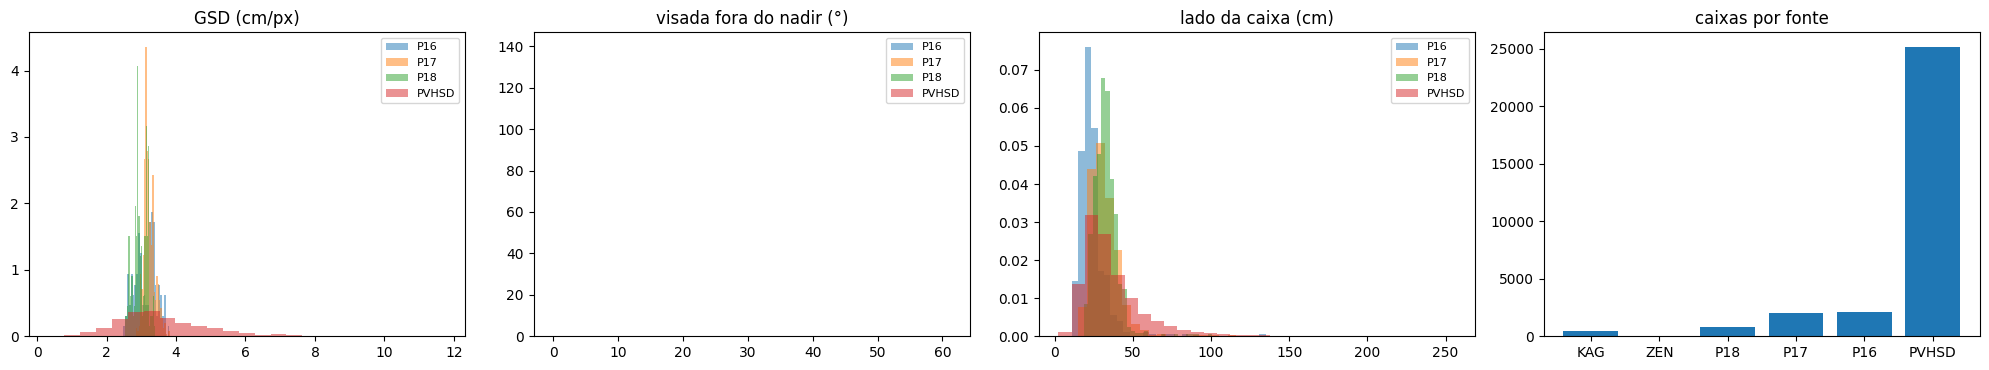

Cobertura do espaço de aquisição (imagens de nível A): buracos = combinações nunca vistas no treino


gsd             (0, 2]  (2, 3]  (3, 4]  (4, 20]
fonte visada                                   
P16   (-1, 10]       0      50      71        0
P17   (-1, 10]       0      27     631        0
P18   (-1, 10]       0     115      80        0
PVHSD (-1, 10]      17      95      59       63
      (10, 20]      61     258     324      369
      (20, 30]     128     459     601      381
      (30, 90]     105     293     328      444

In [17]:
df = pd.DataFrame([dict(fonte=r["fonte"], nivel=r["nivel"], camera=r["camera"], gsd=r.get("gsd"),
                        visada=(90 - abs(r["pitch"])) if r.get("pitch") is not None else None, hora=r.get("hora"),
                        T_mediana=r.get("T_mediana"), caixas=len(r["caixas"]), origem=r["origem"],
                        razao_gsd=r.get("razao_gsd"), gsd_periodo=r.get("gsd_periodo")) for r in INDICE])
display(df.groupby("fonte").agg(imagens=("nivel", "size"), camera=("camera", lambda s: ", ".join(sorted(set(s)))),
                                gsd_med=("gsd", "median"), visada_med=("visada", "median"), hora_med=("hora", "median"),
                                T_med=("T_mediana", "median"), caixas_por_img=("caixas", "mean"),
                                razao_gsd_topo_base=("razao_gsd", "median")).round(2))
lados = [dict(fonte=r["fonte"], lado_cm=math.sqrt((x2 - x1 + 1) * (y2 - y1 + 1)) * r["gsd"])
         for r in INDICE if r.get("gsd") for x1, y1, x2, y2 in r["caixas"]]
fig, ax = plt.subplots(1, 4, figsize=(20, 3.8))
for f, g in df.groupby("fonte"):
    if g.gsd.notna().any():
        ax[0].hist(g.gsd.dropna(), bins=25, alpha=0.5, label=f, density=True)
    if g.visada.notna().any():
        ax[1].hist(g.visada.dropna(), bins=25, alpha=0.5, label=f, density=True)
ax[0].set_title("GSD (cm/px)"); ax[1].set_title("visada fora do nadir (°)")
if lados:
    dl = pd.DataFrame(lados)
    for f, g in dl.groupby("fonte"):
        ax[2].hist(g.lado_cm, bins=30, alpha=0.5, label=f, density=True)
ax[2].set_title("lado da caixa (cm)")
ax[3].bar(df.fonte.unique(), [df[df.fonte == f].caixas.sum() for f in df.fonte.unique()]); ax[3].set_title("caixas por fonte")
for a in ax[:3]:
    a.legend(fontsize=8)
plt.tight_layout(); salvar_fig(fig, "dados_aquisicao"); plt.show()
cob = df[df.nivel == "A"].assign(visada=lambda d: pd.cut(d.visada, [-1, 10, 20, 30, 90]), gsd=lambda d: pd.cut(d.gsd, [0, 2, 3, 4, 20]))
print("Cobertura do espaço de aquisição (imagens de nível A): buracos = combinações nunca vistas no treino")
display(pd.crosstab([cob.fonte, cob.visada], cob.gsd))

## 4. Divisões (folds)
- **LOSO-X:** treina nas outras fontes rotuladas e testa na fonte X inteira (outra câmera ou outro país).
- **IN-X (referência "mesma fonte"):** treina e testa dentro da fonte X, em grupos (voos ou sequências)
  separados. A **perda** de generalização é medida nas mesmas imagens: `IN-X − LOSO-X` no teste do IN-X.
- **TODOS:** treina em todas as fontes; é o modelo final, aplicado ao Kaggle (KAG), à Colômbia (ALF) e à função
  `analisar`.
A validação (limiar) vem sempre de grupos das fontes de treino; o teste nunca participa de escolha nenhuma.

In [18]:
def dividir_grupos(regs, fracs, seed, tentativas=2000):
    imgs = Counter(r["grupo"] for r in regs); cxs = Counter()
    for r in regs:
        cxs[r["grupo"]] += len(r["caixas"])
    grupos = sorted(imgs)
    if len(grupos) < 3:
        return {g: s for g, s in zip(grupos, ("treino", "val", "teste"))}
    rng, melhor, custo_min = random.Random(seed), None, float("inf")
    for _ in range(tentativas):
        ordem = grupos[:]; rng.shuffle(ordem)
        c1 = rng.randint(1, len(ordem) - 2); c2 = rng.randint(c1 + 1, len(ordem) - 1)
        partes = (ordem[:c1], ordem[c1:c2], ordem[c2:])
        custo = sum(abs(sum(imgs[v] for v in g) / sum(imgs.values()) - f) +
                    abs(sum(cxs[v] for v in g) / max(sum(cxs.values()), 1) - f) for g, f in zip(partes, fracs))
        if custo < custo_min:
            melhor, custo_min = partes, custo
    return {g: s for parte, s in zip(melhor, ("treino", "val", "teste")) for g in parte}

def montar_folds():
    rot = lambda f: [r for r in INDICE if r["fonte"] == f]
    F = {}
    val_de = {}
    for f in CFG["fontes_loso"]:          # grupos de validação de cada fonte (os mesmos em todos os folds)
        regs = rot(f); grupos = sorted({r["grupo"] for r in regs}); random.Random(CFG["seed"]).shuffle(grupos)
        cont = Counter(r["grupo"] for r in regs); alvo, acum, gv = CFG["frac_val"] * len(regs), 0, set()
        for g in grupos:
            if acum >= alvo:
                break
            gv.add(g); acum += cont[g]
        val_de[f] = gv
    for X in CFG["fontes_loso"]:
        outras = [r for f in CFG["fontes_loso"] if f != X for r in rot(f)]
        F[f"LOSO-{X}"] = dict(treino=[r["id"] for r in outras if r["grupo"] not in val_de[r["fonte"]]],
                              val=[r["id"] for r in outras if r["grupo"] in val_de[r["fonte"]]], teste=[r["id"] for r in rot(X)])
        sp = dividir_grupos(rot(X), CFG["frac_in"], CFG["seed"])
        F[f"IN-{X}"] = {k: [r["id"] for r in rot(X) if sp[r["grupo"]] == k] for k in ("treino", "val", "teste")}
    todas = [r for f in CFG["fontes_loso"] for r in rot(f)]
    F["TODOS"] = dict(treino=[r["id"] for r in todas if r["grupo"] not in val_de[r["fonte"]]],
                      val=[r["id"] for r in todas if r["grupo"] in val_de[r["fonte"]]],
                      teste=[r["id"] for r in INDICE if r["papel"] in ("teste_fixo", "robustez")])
    for nome, d in F.items():
        g = {k: {POR_ID[i]["grupo"] for i in d[k]} for k in d}
        assert not (g["treino"] & g["val"]) and not (g["treino"] & g["teste"]) and not (g["val"] & g["teste"]), f"vazamento de grupo em {nome}"
        if nome.startswith("LOSO-"):
            assert all(POR_ID[i]["fonte"] != nome[5:] for k in ("treino", "val") for i in d[k]), f"fonte de teste no treino em {nome}"
    assert not any(POR_ID[i]["papel"] in ("teste_fixo", "robustez") for d in F.values() for i in d["treino"] + d["val"])
    return F

FOLDS = montar_folds()
(CACHE_DIR / "folds.json").write_text(json.dumps(FOLDS))
display(pd.DataFrame({n: {k: len(v) for k, v in d.items()} for n, d in FOLDS.items()}).T)

,treino,val,teste
LOSO-PVHSD,1048,305,4023
IN-PVHSD,2449,798,776
LOSO-P16,3887,995,494
IN-P16,293,121,80
LOSO-P17,3744,973,659
IN-P17,388,145,126
LOSO-P18,4113,1063,200
IN-P18,123,29,48
TODOS,4264,1112,349


## 5. Máscara de painel (treinada na ZEN)

In [19]:
ZEN = [r for r in INDICE if r["fonte"] == "ZEN" and r["paineis"]]
arq_painel = CACHE_DIR / "painel.pt"
if arq_painel.exists():
    PAINEL = torch.load(arq_painel, map_location=DEVICE, weights_only=False)
else:
    rng = np.random.default_rng(CFG["seed"])
    Xs, ys, aval = [], [], []
    for r in ZEN:
        d = ler_registro(r); gh, gw = grade(r["h"], r["w"])
        f = features_mapa(d["rgb"], CFG["escala"], gh, gw).float().cpu().numpy()
        cov = cobertura_celulas(r["paineis"], r["h"], r["w"]) >= 0.5
        if r.get("split_oficial") == "train" or len(ZEN) < 20:
            idx = rng.choice(gh * gw, size=min(CFG["max_celulas_painel"], gh * gw), replace=False)
            Xs.append(f[idx]); ys.append(cov[idx])
        if r.get("split_oficial") != "train" or len(ZEN) < 20:
            aval.append((f, cov))
    cab = treinar_logistica(np.concatenate(Xs), np.concatenate(ys).astype(np.float32))
    s = np.concatenate([aplicar_logistica(cab, f) for f, _ in aval]); y = np.concatenate([c for _, c in aval])
    lim = escolher_limiar(s, y.astype(int), np.ones(len(y)))
    PAINEL = dict(cab=cab, limiar=lim, AP=float(average_precision_score(y, s)) if y.any() else float("nan"),
                  IoU=float(((s >= lim) & y).sum() / max(((s >= lim) | y).sum(), 1)))
    torch.save(PAINEL, arq_painel)
CFG["limiar_painel"] = PAINEL["limiar"]                  # usado pela âncora física do R5
print(f"máscara de painel (ZEN, val+teste): AP={PAINEL['AP']:.3f} | IoU={PAINEL['IoU']:.3f} | limiar={PAINEL['limiar']:.3f}")

máscara de painel (ZEN, val+teste): AP=0.994 | IoU=0.912 | limiar=0.487


## 6. Features das três variantes (R0, R1, R2)
Uma passada por imagem calcula: a máscara de painel (sobre a R0), o ΔT_z, as três entradas e as features nas
células guardadas. Primeiro uma PCA por variante é ajustada numa amostra das fontes de treino (não usa rótulos).
As perturbações (seção 8) usam a mesma função.

In [20]:
def processar(r, variantes, pca=None, pert="original", guardar_banco=True):
    d0 = ler_registro(r)
    d, rp = perturbar(d0, r, pert)
    gh, gw = grade(r["h"], r["w"])                       # sempre a grade da imagem ORIGINAL
    f0 = features_mapa(d["rgb"], CFG["escala"], gh, gw)
    painel = aplicar_logistica(PAINEL["cab"], f0.float()).reshape(gh, gw)
    base = d["T"] if (d["T"] is not None and r["nivel"] != "C") else luminancia(d["rgb"])
    z, mad = mapa_z(base, painel, PAINEL["limiar"], r["nivel"])
    dz = dz_celulas(z, gh, gw)
    y = rotulos_celula(r["caixas"], r["h"], r["w"]).ravel()
    ign = rotulos_celula(r["ign"], r["h"], r["w"]).ravel() & (1 - y)
    # Controle de qualidade pela inovação (first-guess check): caixa radiométrica sem contraste térmico é reprovada
    cel_cx = celulas_caixas(r, gw)
    dz_caixa = np.array([float(dz[c].max()) if len(c) else np.nan for c in cel_cx], dtype=np.float32)
    qc_ok = (dz_caixa >= CFG["qc_dz_min"]) | (r["nivel"] == "C")
    y_ok = np.zeros_like(y)
    for c, ok in zip(cel_cx, qc_ok):
        if ok:
            y_ok[c] = 1
    ign_qc = ign | ((y == 1) & (y_ok == 0)).astype(ign.dtype)
    out = dict(y=y.astype(np.uint8), ign=ign.astype(np.uint8), ign_qc=ign_qc.astype(np.uint8), dz=dz.astype(np.float16),
               dz_caixa=dz_caixa, qc_ok=qc_ok.astype(np.uint8), mad=np.float32(mad),
               painel=painel.astype(np.float16), P=preditores(rp, mad, MAD_REF.get(r["nivel"], 1.0)))
    banco, w_banco, aval, w_aval = celulas_guardadas(r, y, ign, dz)
    out.update(banco=banco, w_banco=w_banco, aval=aval, w_aval=w_aval)
    for v in variantes:
        f = f0 if v == "R0" else features_mapa(*entrada_variante(d, rp, v, painel, PAINEL["limiar"]), gh, gw)
        f = f.float()
        if pca is not None:
            f = (f - pca[v]["mu"]) @ pca[v]["V"]
        f = f.cpu().numpy().astype(np.float16)
        out[f"{v}_aval"] = f[aval]
        if guardar_banco:
            out[f"{v}_banco"] = f[banco]
        out[f"{v}_emb"] = f.astype(np.float32).mean(0)
    return out

# MAD de referência por nível (âncora do preditor de contraste): mediana nas fontes de treino
MAD_REF = {}
arq_pca = CACHE_DIR / "pca.pt"
if arq_pca.exists():
    _p = torch.load(arq_pca, map_location=DEVICE, weights_only=False); PCA, MAD_REF = _p["pca"], _p["mad_ref"]
else:
    amostra = random.Random(1).sample([r for r in INDICE if r["papel"] == "loso"], min(300, sum(r["papel"] == "loso" for r in INDICE)))
    cel, mads = defaultdict(list), defaultdict(list)
    rng = np.random.default_rng(1)
    for r in amostra:
        o = processar(r, CFG["variantes"], pca=None, guardar_banco=False)
        mads[r["nivel"]].append(float(o["mad"]))
        for v in CFG["variantes"]:
            k = rng.choice(len(o[f"{v}_aval"]), size=min(64, len(o[f"{v}_aval"])), replace=False)
            cel[v].append(o[f"{v}_aval"][k].astype(np.float32))
    PCA = {}
    for v in CFG["variantes"]:
        X = torch.as_tensor(np.concatenate(cel[v]), device=DEVICE)
        mu = X.mean(0); U, S, Vt = torch.linalg.svd(X - mu, full_matrices=False)
        PCA[v] = dict(mu=mu, V=Vt[:CFG["dim_pca"]].T.contiguous(), var=float((S[:CFG["dim_pca"]] ** 2).sum() / (S ** 2).sum()))
    MAD_REF = {k: float(np.median(v)) for k, v in mads.items()}
    torch.save(dict(pca=PCA, mad_ref=MAD_REF), arq_pca)
print("PCA: variância explicada", {v: round(PCA[v]["var"], 3) for v in PCA}, "| MAD de referência:", MAD_REF)

t0 = time.time()
faltam = [r for r in INDICE if r["papel"] != "painel" and not (pasta("feat") / (chave_de(r["id"]) + ".npz")).exists()]
for k, r in enumerate(faltam):
    salvar_np("feat", chave_de(r["id"]), **processar(r, CFG["variantes"], PCA))
    if (k + 1) % 250 == 0:
        print(f"  {k + 1}/{len(faltam)} imagens ({time.time() - t0:.0f} s)")
empacotar("feat")
print(f"features: {len(faltam)} imagens novas em {time.time() - t0:.0f} s")

PCA: variância explicada {'R0': 0.937, 'R1': 0.94, 'R2': 0.945} | MAD de referência: {'C': 19.310487747192383, 'A': 0.5919013619422913, 'B': 0.6570546627044678}
  250/5725 imagens (115 s)
  500/5725 imagens (219 s)
  750/5725 imagens (312 s)
  1000/5725 imagens (408 s)
  1250/5725 imagens (502 s)
  1500/5725 imagens (597 s)
  1750/5725 imagens (692 s)
  2000/5725 imagens (791 s)
  2250/5725 imagens (887 s)
  2500/5725 imagens (984 s)
  2750/5725 imagens (1078 s)
  3000/5725 imagens (1173 s)
  3250/5725 imagens (1268 s)
  3500/5725 imagens (1366 s)
  3750/5725 imagens (1461 s)
  4000/5725 imagens (1557 s)
  4250/5725 imagens (1652 s)
  4500/5725 imagens (1750 s)
  4750/5725 imagens (1847 s)
  5000/5725 imagens (1945 s)
  5250/5725 imagens (2040 s)
  5500/5725 imagens (2137 s)
features: 5725 imagens novas em 2225 s


### Controle de qualidade dos rótulos
Na assimilação de dados, cada observação passa por um **first-guess check** antes de entrar: se a *inovação*
(observação menos o que se esperava) é grande demais, a observação é tratada como erro grosseiro e rejeitada
(Lahoz & Schneider 2014). Aqui, a "observação" é a caixa do anotador e o "esperado" é o contraste térmico: uma
caixa **radiométrica** cujo ΔT_z máximo fica abaixo de 1 não tem evidência física de hotspot e é **reprovada**.
As células dela ficam fora do treino (nem positivas nem negativas) e as métricas saem com e sem essas caixas.
Nas imagens sem radiometria (nível C) não há como checar, e todas as caixas passam.

In [21]:
qc = []
for r in INDICE:
    if r["papel"] == "painel" or not r["caixas"]:
        continue
    o = carregar_np("feat", chave_de(r["id"]))
    for dzc, ok in zip(o["dz_caixa"], o["qc_ok"]):
        qc.append(dict(fonte=r["fonte"], nivel=r["nivel"], dz_caixa=float(dzc), aprovada=bool(ok)))
QC = pd.DataFrame(qc)
if len(QC):
    tab_qc = QC[QC.nivel != "C"].groupby("fonte").agg(caixas=("aprovada", "size"), reprovadas_pct=("aprovada", lambda a: 100 * (1 - a.mean())),
                                                       dz_mediano=("dz_caixa", "median")).round(2)
    display(tab_qc)
    tab_qc.to_csv(BASE_DIR / "qc_rotulos.csv")

,caixas,reprovadas_pct,dz_mediano
fonte,,,
P16,467,8.78,5.54
P17,2031,7.73,2.64
P18,775,8.00,2.52
PVHSD,25177,0.81,9.66


## 7. Cabeças R0–R5 e avaliação
Cada fold treina as seis cabeças (3 sementes). O limiar de cada cabeça é o de máximo F1 na validação.

O LOSO é um **OSE** (*observing system experiment*) de **negação de dados**, no sentido de Lahoz & Schneider
(2014): tira-se um sistema de observação inteiro (uma fonte, com a sua câmera e o seu anotador) e mede-se o
impacto. A avaliação é sempre em dados independentes, não usados na assimilação.

In [23]:
FONTE_ID = {f: i for i, f in enumerate(CFG["fontes_loso"])}

# Cada arquivo de features é lido do disco uma vez só e fica na memória (~5 GB no volume completo).
_MEM = {}

def feat_mem(chave_np, chave):
    k = (chave_np, chave)
    if k not in _MEM:
        _MEM[k] = carregar_np(chave_np, chave)
    return _MEM[k]

def banco(ids, v):
    partes = defaultdict(list)
    for i, rid in enumerate(ids):
        o = feat_mem("feat", chave_de(rid)); r = POR_ID[rid]
        b = o["banco"]
        sel = o["ign_qc" if CFG["qc_treino"] else "ign"][b] == 0
        partes["F"].append(o[f"{v}_banco"][sel]); partes["y"].append(o["y"][b][sel]); partes["w"].append(o["w_banco"][sel])
        partes["dz"].append(o["dz"][b][sel].astype(np.float32)); partes["img"].append(np.full(int(sel.sum()), i))
        partes["P"].append(np.repeat(o["P"][None], int(sel.sum()), 0))
        partes["temC"].append(np.full(int(sel.sum()), float(r["nivel"] != "C"), np.float32))
        partes["fonte"].append(np.full(int(sel.sum()), FONTE_ID.get(r["fonte"], 0)))
        partes["painel"].append(o["painel"].ravel()[b][sel].astype(np.float32))
    return {k: np.concatenate(v_) for k, v_ in partes.items()}

def itens_aval(c, ids, v, chave_np="feat", sufixo="", qc=False):
    """Aplica a cabeça num lote só (todas as imagens juntas). qc=True: ignora as células das caixas reprovadas e
    mede o recall só nas caixas aprovadas."""
    regs, F, P, DZ, TC = [], [], [], [], []
    for rid in ids:
        o = feat_mem(chave_np, chave_de(rid) + sufixo)
        if o is None:
            continue
        a = o["aval"]
        regs.append((rid, o, len(a)))
        F.append(o[f"{v}_aval"]); P.append(np.repeat(o["P"][None], len(a), 0))
        DZ.append(o["dz"][a].astype(np.float32)); TC.append(np.full(len(a), float(POR_ID[rid]["nivel"] != "C"), np.float32))
    if not regs:
        return []
    s_todos = aplicar_cabeca(c, np.concatenate(F), np.concatenate(P), np.concatenate(DZ), np.concatenate(TC))
    out, ini = [], 0
    for rid, o, n in regs:
        s = s_todos[ini:ini + n]; ini += n
        if "_pos_cx" not in o:                        # posição de cada caixa dentro da amostra de avaliação
            r = POR_ID[rid]; gh, gw = grade(r["h"], r["w"])
            pos_a = {int(i): j for j, i in enumerate(o["aval"])}
            o["_pos_cx"] = [np.array([pos_a[i] for i in cc if i in pos_a], dtype=np.int64) for cc in celulas_caixas(r, gw)]
        a = o["aval"]; ok = o["ign_qc" if qc else "ign"][a] == 0
        caixas = [p for p, aprov in zip(o["_pos_cx"], o["qc_ok"]) if aprov or not qc]
        cx = np.array([s[p].max() if len(p) else -np.inf for p in caixas], dtype=np.float32)
        out.append(dict(id=rid, s=s[ok], y=o["y"][a][ok], w=o["w_aval"][ok], cx=cx))
    return out

_TRAPEZIO = getattr(np, "trapezoid", None) or np.trapz      # nome muda entre versões do numpy

def _ap_auroc(s_o, y_o, w_o):
    """AP e AUROC ponderados sobre escores já ordenados (decrescente). Mesma definição do scikit-learn."""
    tp = np.cumsum(w_o * y_o); fp = np.cumsum(w_o * (1 - y_o))
    fim = np.r_[s_o[1:] != s_o[:-1], True]           # último elemento de cada grupo de empates
    tp, fp = tp[fim], fp[fim]
    Ptot, Ntot = tp[-1], fp[-1]
    if Ptot <= 0 or Ntot <= 0:
        return np.nan, np.nan
    rec = tp / Ptot; prec = tp / np.maximum(tp + fp, 1e-12)
    ap = float(np.sum(np.diff(np.r_[0.0, rec]) * prec))
    auc = float(_TRAPEZIO(np.r_[0.0, rec], np.r_[0.0, fp / Ntot]))
    return ap, auc

def metricas(itens, limiar=None, n_boot=0, seed=0):
    """Ordena os escores uma vez; o bootstrap por imagem só troca os pesos (rápido em milhões de células)."""
    if not itens:
        return {}
    n_i = len(itens)
    s = np.concatenate([it["s"] for it in itens]); y = np.concatenate([it["y"] for it in itens]).astype(np.float64)
    w = np.concatenate([it["w"] for it in itens]).astype(np.float64)
    img = np.repeat(np.arange(n_i), [len(it["s"]) for it in itens])
    ordem = np.argsort(-s, kind="mergesort")
    s_o, y_o, w_o, img_o = s[ordem], y[ordem], w[ordem], img[ordem]
    if limiar is not None:
        acertos = np.array([(it["cx"] >= limiar).sum() for it in itens], dtype=np.float64)
        n_cx = np.array([len(it["cx"]) for it in itens], dtype=np.float64)
        fp_img = np.bincount(img, weights=w * ((s >= limiar) & (y == 0)), minlength=n_i)
    def calc(cont):
        wb = w_o * cont[img_o]
        ap, auc = _ap_auroc(s_o, y_o, wb)
        prev = float((wb * y_o).sum() / wb.sum()) if wb.sum() > 0 else np.nan
        r = dict(AUROC=auc, AP=ap, prevalencia=prev, AP_norm=ap / prev if prev and prev > 0 else np.nan)
        if limiar is not None:
            r["recall_caixa"] = float((cont * acertos).sum() / (cont * n_cx).sum()) if (cont * n_cx).sum() else np.nan
            r["FP_por_img"] = float((cont * fp_img).sum() / n_i)
        return r
    r = calc(np.ones(n_i))
    if n_boot:
        rng = np.random.default_rng(seed)
        bs = defaultdict(list)
        for _ in range(n_boot):
            for k, v_ in calc(np.bincount(rng.integers(0, n_i, n_i), minlength=n_i).astype(np.float64)).items():
                bs[k].append(v_)
        for k, v_ in bs.items():
            v_ = np.array(v_, dtype=float); v_ = v_[np.isfinite(v_)]
            if len(v_):
                r[k + "_lo"], r[k + "_hi"] = np.percentile(v_, 2.5), np.percentile(v_, 97.5)
    return r

CABECAS = ["R0", "R1", "R2", "R3", "R4", "R5"]
MODELOS, LIMIARES, linhas = {}, {}, []
arq_res = CACHE_DIR / "resultados_folds.csv"
t0 = time.time()
for nome, d in FOLDS.items():
    bancos = {}                                          # R2–R5 usam a mesma variante: o banco é montado uma vez
    for cab in CABECAS:
        if cab == "R5" and nome.startswith("IN-"):
            continue                                     # uma fonte só: sem viés de anotação por fonte
        v = VARIANTE_DA_CABECA[cab]
        if v not in bancos:
            bancos[v] = banco(d["treino"], v)
        B = bancos[v]
        if B["y"].sum() == 0:
            continue
        for sem in CFG["sementes"]:
            arq = CACHE_DIR / "cabecas" / f"{nome}_{cab}_{sem}.pt"
            if arq.exists():
                c = torch.load(arq, map_location=DEVICE, weights_only=False)
            else:
                c = treinar_cabeca(B, cab, sem); arq.parent.mkdir(exist_ok=True, parents=True); torch.save(c, arq)
            MODELOS[(nome, cab, sem)] = c
            iv = itens_aval(c, d["val"], v)
            lim = escolher_limiar(np.concatenate([i["s"] for i in iv]), np.concatenate([i["y"] for i in iv]), np.concatenate([i["w"] for i in iv])) if iv else 0.0
            LIMIARES[(nome, cab, sem)] = lim
            for rot, usa_qc in (("todas", False), ("qc", True)):
                por_fonte = defaultdict(list)
                for it in itens_aval(c, d["teste"], v, qc=usa_qc):
                    por_fonte[POR_ID[it["id"]]["fonte"]].append(it)
                for f, its in por_fonte.items():
                    if not any(len(i["cx"]) for i in its):
                        continue                         # fonte sem rótulo (ALF): vai para a seção 9
                    nb = CFG["n_boot"] if (sem == CFG["sementes"][0] and rot == "todas") else 0
                    m = metricas(its, lim, n_boot=nb, seed=sem)
                    linhas.append(dict(fold=nome, cabeca=cab, semente=sem, rotulos=rot, fonte_teste=f, imagens=len(its), **m))
    print(f"{nome}: pronto ({time.time() - t0:.0f} s)")
RES_TUDO = pd.DataFrame(linhas)
RES_TUDO.to_csv(arq_res, index=False)
RES = RES_TUDO[RES_TUDO.rotulos == "todas"]              # padrão: todas as caixas, como vieram
media = RES.groupby(["fold", "fonte_teste", "cabeca"])[["AUROC", "AP_norm", "recall_caixa", "FP_por_img"]].mean().round(3)
display(media.unstack("cabeca"))
dif_qc = (RES_TUDO[RES_TUDO.rotulos == "qc"].groupby(["fold", "fonte_teste", "cabeca"])[["AUROC", "recall_caixa"]].mean()
          - RES.groupby(["fold", "fonte_teste", "cabeca"])[["AUROC", "recall_caixa"]].mean())
print("Efeito do controle de qualidade nas métricas (com QC − todas as caixas):")
display(dif_qc.unstack("cabeca").round(3))


LOSO-PVHSD: pronto (109 s)
IN-PVHSD: pronto (132 s)
LOSO-P16: pronto (210 s)
IN-P16: pronto (222 s)
LOSO-P17: pronto (291 s)
IN-P17: pronto (303 s)
LOSO-P18: pronto (366 s)
IN-P18: pronto (379 s)
TODOS: pronto (452 s)


AUROC                                     AP_norm  \
cabeca                     R0     R1     R2     R3     R4     R5       R0   
fold       fonte_teste                                                      
IN-P16     P16          0.959  0.931  0.933  0.932  0.932    NaN  121.200   
IN-P17     P17          0.943  0.933  0.944  0.946  0.946    NaN  176.393   
IN-P18     P18          0.882  0.830  0.866  0.867  0.862    NaN   98.837   
IN-PVHSD   PVHSD        0.985  0.984  0.983  0.983  0.984    NaN   85.515   
LOSO-P16   P16          0.952  0.904  0.908  0.910  0.911  0.866  208.791   
LOSO-P17   P17          0.911  0.889  0.898  0.897  0.898  0.838   85.920   
LOSO-P18   P18          0.920  0.877  0.896  0.897  0.899  0.801   65.906   
LOSO-PVHSD PVHSD        0.836  0.899  0.908  0.908  0.927  0.947    8.292   
TODOS      KAG          0.790  0.713  0.695  0.709  0.709  0.710   11.213   

                                                   ... recall_caixa         \
cabeca                       R1       R2       R3  ...           R2     R3   
fold       fonte_teste                             ...                       
IN-P16     P16           97.426  133.955  133.358  ...        0.400  0.392   
IN-P17     P17           91.444   96.213   96.560  ...        0.724  0.713   
IN-P18     P18           33.983   43.390   47.001  ...        0.592  0.561   
IN-PVHSD   PVHSD         82.750   76.685   76.830  ...        0.756  0.747   
LOSO-P16   P16          110.505  127.873  128.270  ...        0.532  0.547   
LOSO-P17   P17           40.457   52.926   52.546  ...        0.388  0.388   
LOSO-P18   P18           36.342   50.221   50.471  ...        0.367  0.338   
LOSO-PVHSD PVHSD         22.648   31.423   31.093  ...        0.494  0.454   
TODOS      KAG            6.464    6.384    6.686  ...        0.863  0.897   

                                     FP_por_img                           \
cabeca                     R4     R5         R0       R1      R2      R3   
fold       fonte_teste                                                     
IN-P16     P16          0.375    NaN     10.250    4.000   2.250   2.750   
IN-P17     P17          0.715    NaN      3.333   11.111   8.254   6.984   
IN-P18     P18          0.688    NaN     12.083    9.583  35.833  21.667   
IN-PVHSD   PVHSD        0.736    NaN      8.505   11.495  14.124  12.835   
LOSO-P16   P16          0.526  0.048     10.324    1.660   5.385   6.721   
LOSO-P17   P17          0.408  0.081      9.408    6.555   5.402   5.402   
LOSO-P18   P18          0.348  0.054      7.500    4.300   4.200   3.200   
LOSO-PVHSD PVHSD        0.573  0.600      3.052  172.722  30.365  24.783   
TODOS      KAG          0.846  0.000      7.221    4.928   8.825  13.754   

                                        
cabeca                      R4      R5  
fold       fonte_teste                  
IN-P16     P16           2.250     NaN  
IN-P17     P17           7.460     NaN  
IN-P18     P18          56.667     NaN  
IN-PVHSD   PVHSD        10.722     NaN  
LOSO-P16   P16           5.223   0.162  
LOSO-P17   P17           6.191   1.669  
LOSO-P18   P18           3.500   1.600  
LOSO-PVHSD PVHSD        33.955  32.180  
TODOS      KAG           8.023   0.000  

[9 rows x 24 columns]

Efeito do controle de qualidade nas métricas (com QC − todas as caixas):


AUROC                                    recall_caixa  \
cabeca                     R0     R1     R2     R3     R4     R5           R0   
fold       fonte_teste                                                          
IN-P16     P16         -0.000  0.001  0.001  0.001  0.001    NaN        0.003   
IN-P17     P17         -0.001  0.001  0.002  0.002  0.002    NaN       -0.005   
IN-P18     P18         -0.002  0.000  0.001  0.001  0.001    NaN       -0.005   
IN-PVHSD   PVHSD        0.000  0.000  0.000  0.000  0.000    NaN        0.002   
LOSO-P16   P16          0.000  0.001  0.001  0.001  0.001  0.001       -0.001   
LOSO-P17   P17          0.000  0.004  0.006  0.006  0.006  0.012        0.008   
LOSO-P18   P18         -0.000  0.005  0.004  0.004  0.005  0.012       -0.001   
LOSO-PVHSD PVHSD        0.000  0.001  0.001  0.001  0.001  0.002        0.000   
TODOS      KAG          0.000  0.000  0.000  0.000  0.000  0.000        0.000   

                                                           
cabeca                     R1     R2     R3     R4     R5  
fold       fonte_teste                                     
IN-P16     P16          0.002  0.002  0.002  0.002    NaN  
IN-P17     P17          0.040  0.033  0.034  0.034    NaN  
IN-P18     P18          0.023  0.020  0.025  0.026    NaN  
IN-PVHSD   PVHSD        0.002  0.002  0.002  0.002    NaN  
LOSO-P16   P16          0.008  0.010  0.010  0.010  0.001  
LOSO-P17   P17          0.031  0.028  0.027  0.030  0.007  
LOSO-P18   P18          0.024  0.025  0.022  0.023  0.005  
LOSO-PVHSD PVHSD        0.004  0.004  0.004  0.005  0.005  
TODOS      KAG          0.000  0.000  0.000  0.000  0.000

### Quanto da perda entre fontes cada etapa recupera
Perda = desempenho "mesma fonte" (IN-X) − desempenho da fonte nunca vista (LOSO-X), **nas mesmas imagens** (o
teste do IN-X). A escada mostra quanto dessa perda cada etapa de assimilação recupera.

AUROC_loso                                    perda_AUROC         \
cabeca         R0     R1     R2     R3     R4     R5          R0     R1   
fonte                                                                     
P16         0.945  0.910  0.912  0.913  0.914  0.910       0.013  0.021   
P17         0.921  0.927  0.933  0.932  0.932  0.876       0.022  0.006   
P18         0.934  0.892  0.921  0.920  0.920  0.796      -0.052 -0.062   
PVHSD       0.817  0.889  0.898  0.899  0.921  0.949       0.167  0.096   

                      ... APn_loso                           perda_APn  \
cabeca     R2     R3  ...       R2       R3       R4      R5        R0   
fonte                 ...                                                
P16     0.021  0.019  ...  107.020  107.488  108.764  25.781   -11.916   
P17     0.011  0.015  ...   74.743   73.477   72.349  15.610    57.409   
P18    -0.056 -0.053  ...   64.062   65.897   66.857   6.081   -58.684   
PVHSD   0.085  0.084  ...   25.272   25.346   34.207  39.536    79.567   

                                                 
cabeca      R1      R2      R3      R4       R5  
fonte                                            
P16     -7.441  26.934  25.870  22.982  105.964  
P17     34.699  21.470  23.082  23.110   79.849  
P18    -22.334 -20.672 -18.895 -20.695   40.081  
PVHSD   65.072  51.413  51.484  46.614   41.284  

[4 rows x 24 columns]

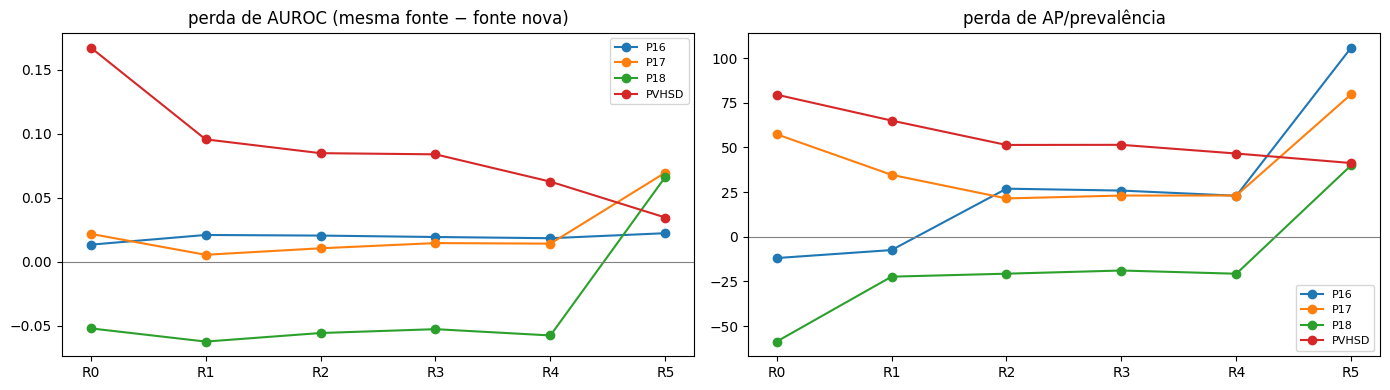

In [24]:
escada = []
for X in CFG["fontes_loso"]:
    ids_teste = FOLDS[f"IN-{X}"]["teste"]
    if not ids_teste:
        continue
    for cab in CABECAS:
        v = VARIANTE_DA_CABECA[cab]
        for sem in CFG["sementes"]:
            if (f"LOSO-{X}", cab, sem) not in MODELOS:
                continue
            m_loso = metricas(itens_aval(MODELOS[(f"LOSO-{X}", cab, sem)], ids_teste, v), LIMIARES[(f"LOSO-{X}", cab, sem)])
            ref = MODELOS.get((f"IN-{X}", cab if cab != "R5" else "R4", sem))
            if ref is None:
                continue
            m_in = metricas(itens_aval(ref, ids_teste, v), LIMIARES[(f"IN-{X}", cab if cab != "R5" else "R4", sem)])
            escada.append(dict(fonte=X, cabeca=cab, semente=sem, AUROC_in=m_in["AUROC"], AUROC_loso=m_loso["AUROC"],
                               APn_in=m_in["AP_norm"], APn_loso=m_loso["AP_norm"]))
ESC = pd.DataFrame(escada)
if len(ESC):
    ESC["perda_AUROC"] = ESC.AUROC_in - ESC.AUROC_loso
    ESC["perda_APn"] = ESC.APn_in - ESC.APn_loso
    e = ESC.groupby(["fonte", "cabeca"])[["AUROC_loso", "perda_AUROC", "APn_loso", "perda_APn"]].mean()
    display(e.unstack("cabeca").round(3))
    ESC.to_csv(BASE_DIR / "escada_perda.csv", index=False)
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    for X, g in ESC.groupby("fonte"):
        gm = g.groupby("cabeca")[["perda_AUROC", "perda_APn"]].mean().reindex(CABECAS)
        ax[0].plot(CABECAS, gm.perda_AUROC, "o-", label=X); ax[1].plot(CABECAS, gm.perda_APn, "o-", label=X)
    ax[0].set_title("perda de AUROC (mesma fonte − fonte nova)"); ax[1].set_title("perda de AP/prevalência")
    for a in ax:
        a.axhline(0, color="gray", lw=0.8); a.legend(fontsize=8)
    plt.tight_layout(); salvar_fig(fig, "escada_assimilacao"); plt.show()

## 8. Invariância por perturbação controlada (a prova principal)
É um **OSSE** (*observing system simulation experiment*): a "verdade" é conhecida (o rótulo da cena) e as
observações de um sistema diferente são **simuladas** a partir dela, como nos estudos de novos satélites
(Lahoz & Schneider 2014). A escala testa o erro de representatividade.

A mesma imagem rotulada é "capturada de outro jeito" (escala ×0,5 e ×0,33, ruído de sensor, desfoque, troca de
paleta) e passa pelo modelo do fold em que a fonte dela ficou de fora. **Se a decisão não depende da
aquisição, a curva fica plana.** O rótulo e a grade de avaliação são os mesmos em todas as perturbações.

perturbações em PVHSD: pronto
perturbações em P16: pronto
perturbações em P17: pronto
perturbações em P18: pronto


queda_AUROC                                    queda_recall  \
cabeca               R0     R1     R2     R3     R4     R5           R0   
perturbacao                                                               
desfoque         -0.010  0.003  0.002  0.002  0.001 -0.002        0.008   
escala_0.33      -0.018 -0.012 -0.025 -0.025 -0.020 -0.063        0.262   
escala_0.5       -0.036 -0.035 -0.034 -0.034 -0.029 -0.049        0.117   
original          0.000  0.000  0.000  0.000  0.000  0.000        0.000   
paleta            0.045  0.005  0.005  0.004  0.005  0.009        0.263   
ruido             0.004  0.011  0.009  0.009  0.010  0.010       -0.014   

                                                
cabeca          R1     R2     R3     R4     R5  
perturbacao                                     
desfoque     0.046  0.041  0.042  0.047  0.016  
escala_0.33  0.206  0.112  0.115  0.151  0.078  
escala_0.5   0.169  0.034  0.040  0.063  0.043  
original     0.000  0.000  0.000  0.000  0.000  
paleta       0.051  0.063  0.058  0.062 -0.000  
ruido        0.050  0.056  0.048  0.057  0.009

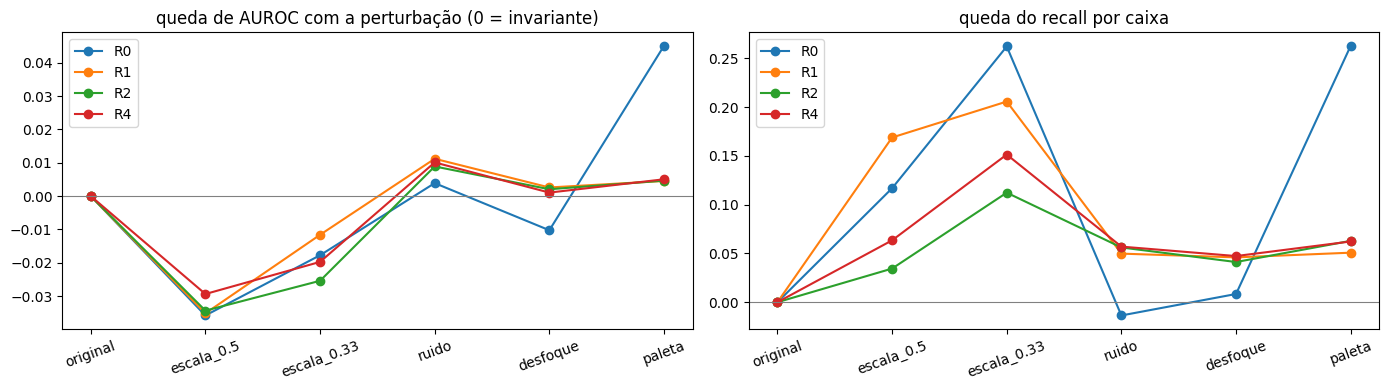

In [25]:
inv = []
for X in CFG["fontes_loso"]:
    ids = FOLDS[f"LOSO-{X}"]["teste"]
    ids = [i for i in random.Random(3).sample(ids, min(CFG["max_perturb"], len(ids))) if POR_ID[i]["caixas"]]
    for pert in CFG["perturbacoes"]:
        suf = "" if pert == "original" else f"__{pert}"
        nome_np = "feat" if pert == "original" else "feat_pert"
        for rid in ids:
            if pert != "original" and not (pasta(nome_np) / (chave_de(rid) + suf + ".npz")).exists():
                salvar_np(nome_np, chave_de(rid) + suf, **processar(POR_ID[rid], CFG["variantes"], PCA, pert=pert, guardar_banco=False))
        empacotar(nome_np)
        for cab in CABECAS:
            c = MODELOS.get((f"LOSO-{X}", cab, CFG["sementes"][0]))
            if c is None:
                continue
            its = itens_aval(c, ids, VARIANTE_DA_CABECA[cab], nome_np, suf)
            m = metricas(its, LIMIARES[(f"LOSO-{X}", cab, CFG["sementes"][0])])
            inv.append(dict(fonte=X, perturbacao=pert, cabeca=cab, **m))
    print(f"perturbações em {X}: pronto")
INV = pd.DataFrame(inv)
INV.to_csv(BASE_DIR / "invariancia_perturbacoes.csv", index=False)
if len(INV):
    base = INV[INV.perturbacao == "original"].set_index(["fonte", "cabeca"])
    INV["queda_AUROC"] = INV.apply(lambda r: base.loc[(r.fonte, r.cabeca), "AUROC"] - r.AUROC, axis=1)
    INV["queda_recall"] = INV.apply(lambda r: base.loc[(r.fonte, r.cabeca), "recall_caixa"] - r.recall_caixa, axis=1)
    display(INV.groupby(["perturbacao", "cabeca"])[["queda_AUROC", "queda_recall"]].mean().unstack("cabeca").round(3))
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    for cab in ["R0", "R1", "R2", "R4"]:
        g = INV[INV.cabeca == cab].groupby("perturbacao")[["queda_AUROC", "queda_recall"]].mean().reindex(CFG["perturbacoes"])
        ax[0].plot(CFG["perturbacoes"], g.queda_AUROC, "o-", label=cab); ax[1].plot(CFG["perturbacoes"], g.queda_recall, "o-", label=cab)
    ax[0].set_title("queda de AUROC com a perturbação (0 = invariante)"); ax[1].set_title("queda do recall por caixa")
    for a in ax:
        a.axhline(0, color="gray", lw=0.8); a.legend(); a.tick_params(axis="x", rotation=20)
    plt.tight_layout(); salvar_fig(fig, "invariancia"); plt.show()

## 9. Fontes nunca vistas e alerta de fora de suporte
- **KAG** (Kaggle, agregado do Roboflow, nível C): teste rotulado com o modelo TODOS.
- **ALF** (Colômbia, Zenmuse XT 336×256, nível B, sem rótulos): só alerta e mapas.

**Alerta:** distância de Mahalanobis do embedding médio da imagem (R2) até as imagens de treino, com limiar no
percentil 99 do treino. Imagem acima do limiar recebe "baixa confiança".

In [26]:
def embs(ids, v="R2"):
    return np.stack([carregar_np("feat", chave_de(i))[f"{v}_emb"] for i in ids])

E_tr = embs(FOLDS["TODOS"]["treino"])
mu_e = E_tr.mean(0); C = np.cov(E_tr.T) + 1e-3 * np.eye(E_tr.shape[1]); Ci = np.linalg.inv(C)
maha = lambda E: np.sqrt(np.einsum("ij,jk,ik->i", E - mu_e, Ci, E - mu_e))
LIM_ALERTA = float(np.percentile(maha(E_tr), 99))
alerta = []
for f in sorted({r["fonte"] for r in INDICE if r["papel"] != "painel"}):
    ids = [r["id"] for r in INDICE if r["fonte"] == f]
    dd = maha(embs(ids))
    alerta.append(dict(fonte=f, imagens=len(ids), alerta_pct=float((dd > LIM_ALERTA).mean() * 100), dist_mediana=float(np.median(dd))))
ALERTA = pd.DataFrame(alerta)
display(ALERTA.round(2))
fixos = RES[(RES.fold == "TODOS")]
if len(fixos):
    display(fixos.groupby(["fonte_teste", "cabeca"])[["AUROC", "AP_norm", "recall_caixa", "FP_por_img"]].mean().unstack("cabeca").round(3))

,fonte,imagens,alerta_pct,dist_mediana
0,KAG,349,69.34,22.61
1,P16,494,2.83,13.48
2,P17,659,2.58,11.98
3,P18,200,1.00,12.83
4,PVHSD,4023,0.94,14.21


AUROC                                   AP_norm                \
cabeca         R0     R1     R2     R3     R4    R5      R0     R1     R2   
fonte_teste                                                                 
KAG          0.79  0.713  0.695  0.709  0.709  0.71  11.213  6.464  6.384   

                    ... recall_caixa                    FP_por_img         \
cabeca          R3  ...           R2     R3     R4   R5         R0     R1   
fonte_teste         ...                                                     
KAG          6.686  ...        0.863  0.897  0.846  0.0      7.221  4.928   

                                        
cabeca          R2      R3     R4   R5  
fonte_teste                             
KAG          8.825  13.754  8.023  0.0  

[1 rows x 24 columns]

## 10. O que a assimilação aprendeu
- **β (viés tipo VarBC):** quanto cada propriedade da aquisição desloca a decisão, em logit.
- **K(m) = K_max·B/(B+R) (ganho de Kalman):** quanto a evidência física pesa em cada aquisição; `b_obs` diz que
  metadado aumenta o erro da observação física.
- **α, γ por fonte:** o desvio do critério de anotação de cada dataset em relação à âncora física.

In [27]:
c5 = MODELOS.get(("TODOS", "R5", CFG["sementes"][0])) or MODELOS.get(("TODOS", "R4", CFG["sementes"][0]))
if c5 is not None:
    m = c5["m"]
    print("β = viés VarBC (logit); b_obs > 0 = o metadado aumenta o erro da observação física (menos peso no ΔT_z)")
    display(pd.DataFrame(dict(preditor=NOMES_P, beta=m.beta.detach().cpu().numpy(), b_obs=m.b_obs.detach().cpu().numpy())).round(3))
    if c5["cabeca"] == "R5":
        n = len(CFG["fontes_loso"])
        print("α, γ = desvio do critério de anotação de cada fonte em relação à âncora física (α = γ = 0)")
        display(pd.DataFrame(dict(fonte=CFG["fontes_loso"], alfa=m.alfa.detach().cpu().numpy()[:n],
                                  gama=m.gama.detach().cpu().numpy()[:n])).round(3))
    Ps = np.stack([carregar_np("feat", chave_de(i))["P"] for i in FOLDS["TODOS"]["treino"]])
    with torch.no_grad():
        K = m.ganho(torch.as_tensor(Ps, device=DEVICE)).cpu().numpy()
    fontes_tr = [POR_ID[i]["fonte"] for i in FOLDS["TODOS"]["treino"]]
    print("Ganho K(m) = K_max·B/(B+R) por fonte de treino:")
    display(pd.DataFrame(dict(fonte=fontes_tr, K=K)).groupby("fonte").K.describe().round(3))

β = viés VarBC (logit); b_obs > 0 = o metadado aumenta o erro da observação física (menos peso no ΔT_z)


,preditor,beta,b_obs
0,1-cos(visada),-0.106,-0.067
1,log(GSD/3),0.255,0.022
2,log(MAD/MAD_ref),0.627,0.044
3,sen(hora),0.030,-0.024
4,cos(hora),0.832,0.022
5,falta_geometria,1.005,0.027
6,falta_hora,1.206,0.000
7,nivel_C,1.206,0.000


α, γ = desvio do critério de anotação de cada fonte em relação à âncora física (α = γ = 0)


,fonte,alfa,gama
0,PVHSD,1.652,-1.156
1,P16,-0.099,-0.542
2,P17,1.289,-1.160
3,P18,1.702,-1.117


Ganho K(m) = K_max·B/(B+R) por fonte de treino:


,count,mean,std,min,25%,50%,75%,max
fonte,,,,,,,,
P16,377.0,1.265,0.006,1.249,1.263,1.263,1.263,1.297
P17,520.0,1.254,0.010,1.236,1.245,1.252,1.263,1.276
P18,151.0,1.267,0.010,1.246,1.260,1.270,1.275,1.287
PVHSD,3216.0,1.288,0.018,1.224,1.275,1.289,1.300,1.349


## 11. Mapas de exemplo e a função `analisar`
`analisar(jpg_bytes)` é o produto: recebe **qualquer** JPEG térmico, decide o nível (A/B/C), aplica o modelo TODOS
e devolve o mapa de escore, o nível, o alerta e os termos usados.

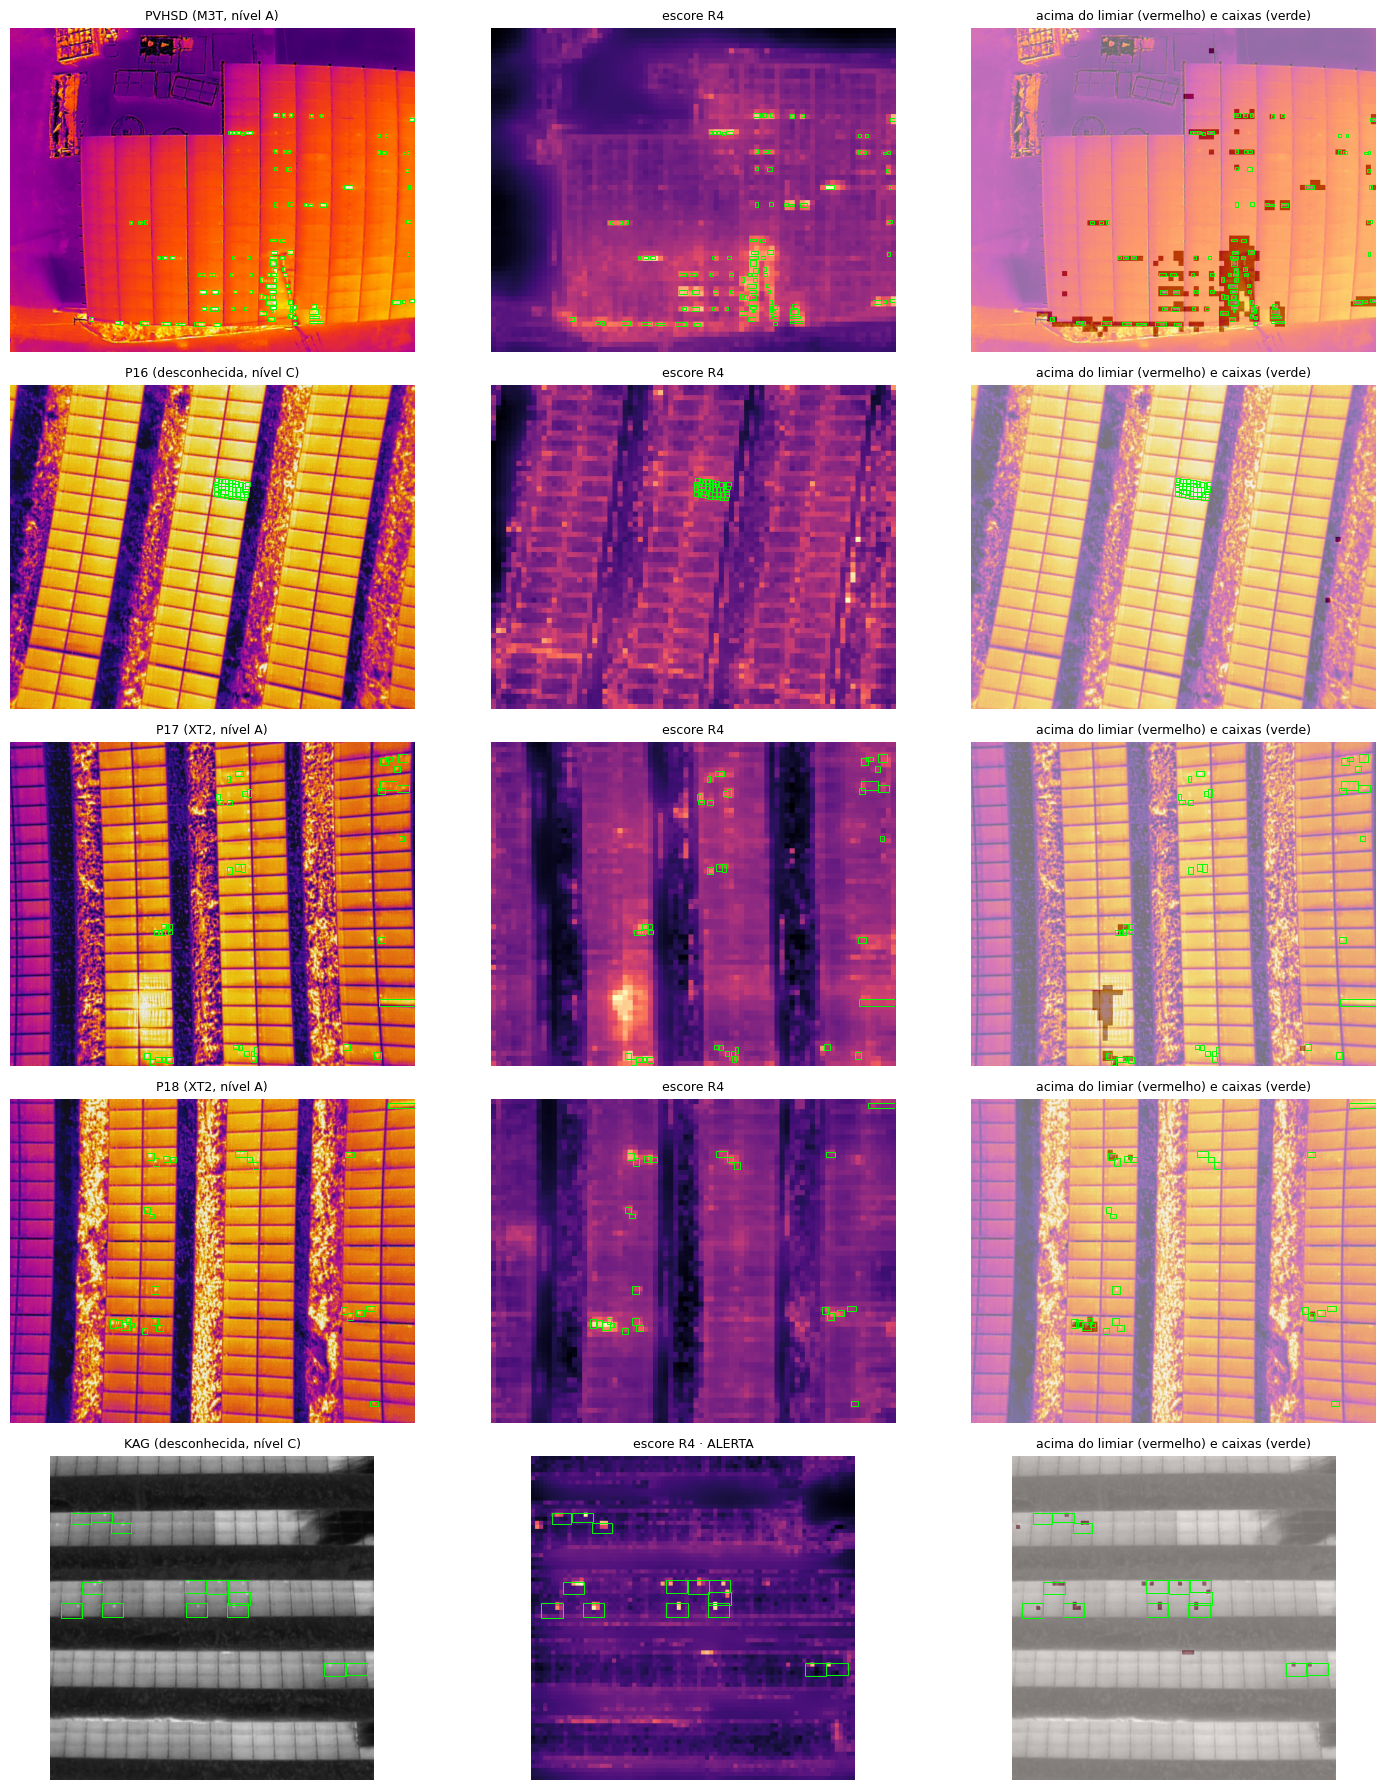

In [28]:
def analisar(jpg_bytes, cabeca="R4"):
    import tempfile
    d = ler_qualquer(jpg_bytes)
    meta = d["meta"]; gsd = gsd_centro(meta, d["hfov"], d["w"]) if d["T"] is not None else None
    nivel = "C" if d["T"] is None else ("A" if gsd and 0.3 <= gsd <= 15 else "B")
    r = dict(id="analisar", h=d["h"], w=d["w"], nivel=nivel, gsd=gsd, pitch=meta["pitch"], hora=meta["hora"], caixas=[], ign=[])
    gh, gw = grade(d["h"], d["w"])
    f0 = features_mapa(d["rgb"], CFG["escala"], gh, gw)
    painel = aplicar_logistica(PAINEL["cab"], f0.float()).reshape(gh, gw)
    base = d["T"] if nivel != "C" else luminancia(d["rgb"])
    z, mad = mapa_z(base, painel, PAINEL["limiar"], nivel)
    v = VARIANTE_DA_CABECA[cabeca]
    f = f0 if v == "R0" else features_mapa(*entrada_variante(d, r, v, painel, PAINEL["limiar"]), gh, gw)
    f = ((f.float() - PCA[v]["mu"]) @ PCA[v]["V"]).cpu().numpy()
    c = MODELOS[("TODOS", cabeca, CFG["sementes"][0])]
    P = preditores(r, mad, MAD_REF.get(nivel, 1.0))
    s = aplicar_cabeca(c, f, P, dz_celulas(z, gh, gw), float(nivel != "C"))
    dist = float(maha(f.mean(0, keepdims=True).astype(np.float32))[0]) if v == "R2" else None
    return dict(mapa=s.reshape(gh, gw), nivel=nivel, limiar=LIMIARES[("TODOS", cabeca, CFG["sementes"][0])],
                alerta=bool(dist is not None and dist > LIM_ALERTA), dist_suporte=dist, camera=d["camera"],
                termos=TERMOS[cabeca] if nivel != "C" else [t for t in TERMOS[cabeca] if t != "ganho"])

exemplos = []
for f in ["PVHSD", "P16", "P17", "P18", "KAG", "ALF"]:
    cand = [r for r in INDICE if r["fonte"] == f and (r["caixas"] or f == "ALF")]
    if cand:
        exemplos.append(max(cand, key=lambda r: len(r["caixas"])))
if exemplos and ("TODOS", "R4", CFG["sementes"][0]) in MODELOS:
    fig, ax = plt.subplots(len(exemplos), 3, figsize=(15, 3.6 * len(exemplos)), squeeze=False)
    for i, r in enumerate(exemplos):
        res = analisar((DADOS / r["arquivo"]).read_bytes())
        d = ler_registro(r)
        ax[i, 0].imshow(d["rgb"]); ax[i, 0].set_title(f"{r['fonte']} ({r['camera']}, nível {res['nivel']})", fontsize=9)
        ax[i, 1].imshow(np.kron(res["mapa"], np.ones((CEL, CEL)))[:r["h"], :r["w"]], cmap="magma")
        ax[i, 1].set_title(f"escore R4{' · ALERTA' if res['alerta'] else ''}", fontsize=9)
        ax[i, 2].imshow(d["rgb"]); ax[i, 2].imshow(np.kron(res["mapa"] >= res["limiar"], np.ones((CEL, CEL)))[:r["h"], :r["w"]], cmap="Reds", alpha=0.45)
        ax[i, 2].set_title("acima do limiar (vermelho) e caixas (verde)", fontsize=9)
        for a in ax[i]:
            for x1, y1, x2, y2 in r["caixas"]:
                a.add_patch(mpatches.Rectangle((x1, y1), x2 - x1 + 1, y2 - y1 + 1, fill=False, ec="lime", lw=0.7))
            a.axis("off")
    plt.tight_layout(); salvar_fig(fig, "mapas_exemplo"); plt.show()

## 12. Resultados consolidados

In [29]:
resumo = RES.groupby(["fold", "fonte_teste", "cabeca"]).agg(
    AUROC=("AUROC", "mean"), AP_norm=("AP_norm", "mean"), recall_caixa=("recall_caixa", "mean"), FP_por_img=("FP_por_img", "mean"),
    AUROC_lo=("AUROC_lo", "first"), AUROC_hi=("AUROC_hi", "first")).reset_index()
resumo.to_csv(BASE_DIR / "resultados_v3.csv", index=False)
ALERTA.to_csv(BASE_DIR / "alerta_suporte.csv", index=False)
print("Arquivos salvos em", BASE_DIR)
display(resumo[resumo.fold.str.startswith("LOSO")].pivot_table(index=["fonte_teste"], columns="cabeca", values="AUROC").round(3))

Arquivos salvos em /content/drive/MyDrive/SCC0287_Solar_v3


cabeca,R0,R1,R2,R3,R4,R5
fonte_teste,,,,,,
P16,0.952,0.904,0.908,0.910,0.911,0.866
P17,0.911,0.889,0.898,0.897,0.898,0.838
P18,0.920,0.877,0.896,0.897,0.899,0.801
PVHSD,0.836,0.899,0.908,0.908,0.927,0.947
